In [1]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path
from IPython.display import display

# Project folders
PROJECT_DIR = Path.cwd().parent
DATASETS_DIR = PROJECT_DIR / "Datasets"
MODELS_DIR = PROJECT_DIR / "Models"

DATASETS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Load original dataset
DATA_PATH = DATASETS_DIR / "humansignal_dataset.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset:", DATA_PATH.resolve())
print("Datasets folder:", DATASETS_DIR.resolve())
print("Models folder:", MODELS_DIR.resolve())
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset: D:\HumanSignal\AI\Datasets\humansignal_dataset.csv
Datasets folder: D:\HumanSignal\AI\Datasets
Models folder: D:\HumanSignal\AI\Models
Shape: (2832, 27)


,user_id,session_id,window_start,is_baseline,mean_rt_ms,std_rt_ms,error_rate,mean_iki_ms,std_iki_ms,pause_count,...,error_rate_z,mean_iki_ms_z,std_iki_ms_z,pause_count_z,max_pause_ms_z,keys_per_sec_z,mouse_speed_mean_z,mouse_jitter_z,task_switches_z,label
0,U01,S001,0,1,252.0,38.0,0.0227,195.6,33.9,1,...,-0.330,-0.735,-0.753,0.596,0.595,-0.218,0.125,0.600,-0.290,Normal
1,U01,S001,5,1,261.9,42.4,0.1136,195.7,29.2,1,...,3.562,-0.728,-1.693,0.596,2.145,-0.178,-0.533,-0.710,3.043,Normal
2,U01,S001,10,1,268.7,40.9,0.0465,192.4,32.6,1,...,0.689,-0.955,-1.013,0.596,0.863,-0.339,0.512,0.096,-0.290,Normal
3,U01,S001,15,1,290.8,37.6,0.0238,197.8,39.8,1,...,-0.283,-0.583,0.427,0.596,0.404,-0.541,-1.099,-0.256,-0.290,Normal
4,U01,S001,20,1,296.1,41.4,0.0667,185.7,32.8,1,...,1.554,-1.417,-0.973,0.596,1.800,0.024,-0.917,0.802,-0.290,Normal


In [2]:
required_columns = [
    "user_id",
    "session_id",
    "window_start",
    "mean_rt_ms",
    "std_rt_ms",
    "error_rate",
    "mean_iki_ms",
    "std_iki_ms",
    "pause_count",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "mouse_jitter",
    "task_switches",
    "is_baseline",
    "label",
]

missing_columns = sorted(set(required_columns) - set(df.columns))

if missing_columns:
    print("FAIL: Missing required columns:", missing_columns)
else:
    print("PASS: All required columns are present.")

z_columns = [c for c in df.columns if c.endswith("_z")]

print("\nNumber of standardized features:", len(z_columns))
print("Standardized columns:", z_columns)

PASS: All required columns are present.

Number of standardized features: 11
Standardized columns: ['mean_rt_ms_z', 'std_rt_ms_z', 'error_rate_z', 'mean_iki_ms_z', 'std_iki_ms_z', 'pause_count_z', 'max_pause_ms_z', 'keys_per_sec_z', 'mouse_speed_mean_z', 'mouse_jitter_z', 'task_switches_z']


In [3]:
print("Total missing values:", int(df.isna().sum().sum()))

missing_summary = df.isna().sum()
print("\nColumns with missing values:")
display(missing_summary[missing_summary > 0])

print("\nExact duplicate rows:", int(df.duplicated().sum()))

print(
    "Duplicate user-session-window combinations:",
    int(df.duplicated(
        subset=["user_id", "session_id", "window_start"]
    ).sum())
)

Total missing values: 0

Columns with missing values:


Series([], dtype: int64)


Exact duplicate rows: 0
Duplicate user-session-window combinations: 0


In [4]:
range_checks = {
    "mean_rt_ms": (0, None),
    "std_rt_ms": (0, None),
    "error_rate": (0, 1),
    "mean_iki_ms": (0, None),
    "std_iki_ms": (0, None),
    "pause_count": (0, None),
    "max_pause_ms": (0, None),
    "keys_per_sec": (0, None),
    "mouse_speed_mean": (0, None),
    "mouse_jitter": (0, None),
    "task_switches": (0, None),
    "window_start": (0, None),
}

for column, (lower, upper) in range_checks.items():
    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors="coerce")
    invalid = values.isna() | (values < lower)

    if upper is not None:
        invalid |= values > upper

    print(f"{column}: {int(invalid.sum())} invalid rows")

print("\nCheck that count features contain whole numbers:")
for column in ["pause_count", "task_switches"]:
    if column in df.columns:
        values = pd.to_numeric(df[column], errors="coerce")
        invalid = values.notna() & (values % 1 != 0)
        print(f"{column}: {int(invalid.sum())} non-integer values")

mean_rt_ms: 0 invalid rows
std_rt_ms: 0 invalid rows
error_rate: 0 invalid rows
mean_iki_ms: 0 invalid rows
std_iki_ms: 0 invalid rows
pause_count: 0 invalid rows
max_pause_ms: 0 invalid rows
keys_per_sec: 0 invalid rows
mouse_speed_mean: 0 invalid rows
mouse_jitter: 0 invalid rows
task_switches: 0 invalid rows
window_start: 0 invalid rows

Check that count features contain whole numbers:
pause_count: 0 non-integer values
task_switches: 0 non-integer values


In [5]:
expected_labels = {
    "Normal",
    "Focused",
    "Fatigued",
    "Overloaded",
}

print("Label counts:")
display(df["label"].value_counts(dropna=False))

print("\nLabel proportions:")
display(df["label"].value_counts(normalize=True, dropna=False).round(4))

actual_labels = set(df["label"].dropna().unique())

print("\nUnexpected labels:", actual_labels - expected_labels)
print("Missing expected labels:", expected_labels - actual_labels)

Label counts:


label
Normal        1536
Focused        432
Fatigued       432
Overloaded     432
Name: count, dtype: int64


Label proportions:


label
Normal        0.5424
Focused       0.1525
Fatigued      0.1525
Overloaded    0.1525
Name: proportion, dtype: float64


Unexpected labels: set()
Missing expected labels: set()


In [6]:
print("Baseline flag counts:")
display(df["is_baseline"].value_counts(dropna=False))

session_summary = (
    df.groupby(["user_id", "session_id"], dropna=False)
      .agg(
          total_windows=("window_start", "size"),
          baseline_windows=("is_baseline", "sum"),
          start_time=("window_start", "min"),
          end_time=("window_start", "max"),
          labels=("label", lambda x: sorted(x.dropna().unique()))
      )
      .reset_index()
)

display(session_summary)

print("\nBaseline window counts per session:")
display(session_summary["baseline_windows"].value_counts().sort_index())


baseline_mask = df["is_baseline"].eq(1)

print(
    "Baseline rows:",
    int(baseline_mask.sum())
)

print(
    "Baseline rows not labeled Normal:",
    int((baseline_mask & df["label"].ne("Normal")).sum())
)

print(
    "Baseline duration implied by 10-second windows:",
    int(df.loc[baseline_mask].groupby(
        ["user_id", "session_id"]
    ).size().median() * 10),
    "seconds (median per session)"
)

Baseline flag counts:


is_baseline
0    1728
1    1104
Name: count, dtype: int64

,user_id,session_id,total_windows,baseline_windows,start_time,end_time,labels
0,U01,S001,59,23,0,290,[Normal]
1,U01,S002,59,23,0,290,"[Focused, Normal]"
2,U01,S003,59,23,0,290,"[Fatigued, Normal]"
3,U01,S004,59,23,0,290,"[Normal, Overloaded]"
4,U02,S005,59,23,0,290,[Normal]
5,U02,S006,59,23,0,290,"[Focused, Normal]"
6,U02,S007,59,23,0,290,"[Fatigued, Normal]"
7,U02,S008,59,23,0,290,"[Normal, Overloaded]"
8,U03,S009,59,23,0,290,[Normal]
9,U03,S010,59,23,0,290,"[Focused, Normal]"



Baseline window counts per session:


baseline_windows
23    48
Name: count, dtype: int64

Baseline rows: 1104
Baseline rows not labeled Normal: 0
Baseline duration implied by 10-second windows: 230 seconds (median per session)


In [7]:
report = {
    "rows": len(df),
    "columns": len(df.columns),
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "unique_users": int(df["user_id"].nunique()),
    "unique_sessions": int(
        df[["user_id", "session_id"]]
        .drop_duplicates()
        .shape[0]
    ),
    "standardized_features": len(z_columns),
    "labels": df["label"].value_counts().to_dict(),
}

report_df = pd.DataFrame(
    list(report.items()),
    columns=["check", "result"]
)

display(report_df)

report_df.to_csv(
    DATASETS_DIR / "humansignal_initial_validation_report.csv",
    index=False
)

print("Validation report saved.")

,check,result
0,rows,2832
1,columns,27
2,missing_values,0
3,duplicate_rows,0
4,unique_users,12
5,unique_sessions,48
6,standardized_features,11
7,labels,"{'Normal': 1536, 'Focused': 432, 'Fatigued': 4..."


Validation report saved.


In [8]:
raw_features = [
    "mean_rt_ms",
    "std_rt_ms",
    "error_rate",
    "mean_iki_ms",
    "std_iki_ms",
    "pause_count",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "mouse_jitter",
    "task_switches",
]

z_audit = []

for feature in raw_features:
    z_col = f"{feature}_z"

    if z_col not in df.columns:
        z_audit.append({
            "feature": feature,
            "status": "Missing z column"
        })
        continue

    errors = []

    for _, group in df.groupby(["user_id", "session_id"]):
        baseline = group.loc[
            group["is_baseline"].eq(1), feature
        ]

        mean = baseline.mean()
        std = baseline.std(ddof=0)

        if std > 1e-12:
            expected_z = (group[feature] - mean) / std
            errors.extend(
                np.abs(expected_z - group[z_col]).tolist()
            )

    max_error = max(errors) if errors else np.nan

    z_audit.append({
        "feature": feature,
        "max_abs_difference": max_error,
        "status": (
            "PASS" if np.isfinite(max_error)
            and max_error < 1e-5 else "INVESTIGATE"
        )
    })

display(pd.DataFrame(z_audit))

,feature,max_abs_difference,status
0,mean_rt_ms,0.386485,INVESTIGATE
1,std_rt_ms,4.069867,INVESTIGATE
2,error_rate,0.270381,INVESTIGATE
3,mean_iki_ms,1.709813,INVESTIGATE
4,std_iki_ms,2.854110,INVESTIGATE
5,pause_count,7.610279,INVESTIGATE
6,max_pause_ms,0.226164,INVESTIGATE
7,keys_per_sec,0.201682,INVESTIGATE
8,mouse_speed_mean,0.172793,INVESTIGATE
9,mouse_jitter,0.538215,INVESTIGATE


In [9]:
z_diagnostic = []

for feature in raw_features:
    z_col = f"{feature}_z"

    if z_col not in df.columns:
        continue

    for ddof in [0, 1]:
        errors = []
        zero_std_sessions = 0

        for _, group in df.groupby(["user_id", "session_id"]):
            baseline = group.loc[
                group["is_baseline"].eq(1), feature
            ]

            baseline_std = baseline.std(ddof=ddof)

            if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
                zero_std_sessions += 1
                continue

            expected_z = (
                group[feature] - baseline.mean()
            ) / baseline_std

            errors.extend(
                np.abs(expected_z - group[z_col]).to_numpy()
            )

        z_diagnostic.append({
            "feature": feature,
            "ddof": ddof,
            "max_abs_error": max(errors) if errors else np.nan,
            "mean_abs_error": np.mean(errors) if errors else np.nan,
            "zero_std_sessions": zero_std_sessions
        })

diagnostic_df = pd.DataFrame(z_diagnostic)

display(
    diagnostic_df.sort_values(
        ["feature", "ddof"]
    ).round(6)
)

,feature,ddof,max_abs_error,mean_abs_error,zero_std_sessions
4,error_rate,0,0.270381,0.025854,0
5,error_rate,1,0.112220,0.000756,0
14,keys_per_sec,0,0.201682,0.026614,0
15,keys_per_sec,1,0.000500,0.000248,0
12,max_pause_ms,0,0.226164,0.023228,0
13,max_pause_ms,1,0.000500,0.000253,0
6,mean_iki_ms,0,1.709813,0.074452,0
7,mean_iki_ms,1,1.527399,0.044628,0
0,mean_rt_ms,0,0.386485,0.047593,0
1,mean_rt_ms,1,0.289165,0.003517,0


In [10]:
df_norm = df.copy()

raw_features = [
    "mean_rt_ms",
    "std_rt_ms",
    "error_rate",
    "mean_iki_ms",
    "std_iki_ms",
    "pause_count",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "mouse_jitter",
    "task_switches",
]

normalization_report = []

for feature in raw_features:
    z_col = f"{feature}_z"
    df_norm[z_col] = np.nan

    zero_variance_sessions = 0

    for _, group in df_norm.groupby(
        ["user_id", "session_id"], sort=False
    ):
        baseline_mask = group["is_baseline"].eq(1)
        baseline = group.loc[baseline_mask, feature]

        # Use sample standard deviation (ddof=1).
        baseline_mean = baseline.mean()
        baseline_std = baseline.std(ddof=1)

        if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
            # A z-score cannot be defined reliably.
            # Use zero to represent no measurable deviation
            # for this feature within this session.
            df_norm.loc[group.index, z_col] = 0.0
            zero_variance_sessions += 1
        else:
            df_norm.loc[group.index, z_col] = (
                group[feature] - baseline_mean
            ) / baseline_std

    normalization_report.append({
        "feature": feature,
        "zero_variance_sessions": zero_variance_sessions,
        "missing_z_values": int(df_norm[z_col].isna().sum()),
        "max_abs_z": float(df_norm[z_col].abs().max()),
    })

display(pd.DataFrame(normalization_report))

,feature,zero_variance_sessions,missing_z_values,max_abs_z
0,mean_rt_ms,0,0,16.681819
1,std_rt_ms,0,0,16.214906
2,error_rate,0,0,12.049570
3,mean_iki_ms,0,0,8.139196
4,std_iki_ms,0,0,13.405987
5,pause_count,0,0,17.053017
6,max_pause_ms,0,0,10.063979
7,keys_per_sec,0,0,8.975950
8,mouse_speed_mean,0,0,7.666491
9,mouse_jitter,0,0,14.434819


In [11]:
z_columns = [f"{feature}_z" for feature in raw_features]

assert df_norm[z_columns].notna().all().all()
assert np.isfinite(df_norm[z_columns].to_numpy()).all()

output_path = DATASETS_DIR / "humansignal_dataset_normalized.csv"
df_norm.to_csv(output_path, index=False)

print("Normalized dataset saved:", output_path)
print("Shape:", df_norm.shape)
print("All normalized values are finite.")

Normalized dataset saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_normalized.csv
Shape: (2832, 27)
All normalized values are finite.


In [12]:
baseline_df = df_norm[df_norm["is_baseline"] == 1]

baseline_check = baseline_df[
    [f"{feature}_z" for feature in raw_features]
].agg(["mean", "std", "min", "max"]).T

display(baseline_check.round(4))

,mean,std,min,max
mean_rt_ms_z,-0.0,0.9785,-2.6179,3.1539
std_rt_ms_z,-0.0,0.9785,-2.7777,3.0915
error_rate_z,-0.0,0.9785,-1.6135,3.6932
mean_iki_ms_z,-0.0,0.9785,-3.0180,3.0815
std_iki_ms_z,0.0,0.9785,-2.3668,3.1062
pause_count_z,-0.0,0.9785,-0.9897,4.5873
max_pause_ms_z,0.0,0.9785,-1.1357,4.5873
keys_per_sec_z,-0.0,0.9785,-3.3887,2.6276
mouse_speed_mean_z,-0.0,0.9785,-3.0428,3.4709
mouse_jitter_z,-0.0,0.9785,-2.4695,2.9880


In [13]:

import pandas as pd
import numpy as np

# Use the normalized dataset and raw feature list from previous cells
z_cols = [f"{feature}_z" for feature in raw_features]

# 1. Find the largest absolute z-score for each feature
extreme_summary = []

for feature in raw_features:
    z_col = f"{feature}_z"
    idx = df_norm[z_col].abs().idxmax()
    row = df_norm.loc[idx]

    extreme_summary.append({
        "feature": feature,
        "max_abs_z": abs(row[z_col]),
        "z_score": row[z_col],
        "raw_value": row[feature],
        "user_id": row["user_id"],
        "session_id": row["session_id"],
        "window_start": row["window_start"],
        "is_baseline": row["is_baseline"],
        "label": row["label"]
    })

extreme_summary_df = pd.DataFrame(extreme_summary)

display(
    extreme_summary_df
    .sort_values("max_abs_z", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

# 2. Check baseline standard deviations for every session
baseline_std_records = []

for (user_id, session_id), group in df_norm.groupby(
    ["user_id", "session_id"]
):
    baseline = group.loc[group["is_baseline"] == 1]

    for feature in raw_features:
        baseline_std_records.append({
            "user_id": user_id,
            "session_id": session_id,
            "feature": feature,
            "baseline_std": baseline[feature].std(ddof=1),
            "baseline_mean": baseline[feature].mean(),
            "baseline_windows": len(baseline)
        })

baseline_std_df = pd.DataFrame(baseline_std_records)

print("\nSessions with the smallest baseline standard deviations:")
display(
    baseline_std_df
    .sort_values("baseline_std")
    .head(20)
    .round(5)
    .reset_index(drop=True)
)

# 3. Inspect the 20 rows with the largest absolute z-scores
long_z = df_norm.melt(
    id_vars=[
        "user_id", "session_id", "window_start",
        "is_baseline", "label"
    ],
    value_vars=z_cols,
    var_name="z_feature",
    value_name="z_score"
)

print("\n20 largest absolute z-scores:")
display(
    long_z.assign(abs_z=long_z["z_score"].abs())
    .nlargest(20, "abs_z")
    .drop(columns="abs_z")
    .round(4)
    .reset_index(drop=True)
)


,feature,max_abs_z,z_score,raw_value,user_id,session_id,window_start,is_baseline,label
0,pause_count,17.0530,17.0530,5.0000,U03,S011,220,0,Fatigued
1,mean_rt_ms,16.6818,16.6818,469.3000,U02,S007,280,0,Fatigued
2,std_rt_ms,16.2149,16.2149,119.5000,U12,S048,140,0,Overloaded
3,mouse_jitter,14.4348,14.4348,4.3900,U03,S012,125,0,Overloaded
4,std_iki_ms,13.4060,13.4060,139.0000,U02,S008,200,0,Overloaded
5,error_rate,12.0496,12.0496,0.2143,U09,S035,250,0,Fatigued
6,max_pause_ms,10.0640,10.0640,3328.0000,U03,S012,210,0,Overloaded
7,task_switches,9.3831,9.3831,2.0000,U06,S024,210,0,Overloaded
8,keys_per_sec,8.9759,-8.9759,1.1700,U03,S011,220,0,Fatigued
9,mean_iki_ms,8.1392,8.1392,206.0000,U12,S047,280,0,Fatigued



Sessions with the smallest baseline standard deviations:


,user_id,session_id,feature,baseline_std,baseline_mean,baseline_windows
0,U01,S003,task_switches,0.00000,0.00000,23
1,U11,S044,task_switches,0.00000,0.00000,23
2,U11,S041,task_switches,0.00000,0.00000,23
3,U03,S010,task_switches,0.00000,0.00000,23
4,U09,S034,task_switches,0.00000,0.00000,23
5,U03,S012,task_switches,0.00000,0.00000,23
6,U04,S013,task_switches,0.00000,0.00000,23
7,U04,S016,task_switches,0.00000,0.00000,23
8,U06,S021,task_switches,0.00000,0.00000,23
9,U08,S029,task_switches,0.00000,0.00000,23



20 largest absolute z-scores:


,user_id,session_id,window_start,is_baseline,label,z_feature,z_score
0,U03,S011,220,0,Fatigued,pause_count_z,17.0530
1,U02,S007,280,0,Fatigued,mean_rt_ms_z,16.6818
2,U12,S048,140,0,Overloaded,std_rt_ms_z,16.2149
3,U03,S012,125,0,Overloaded,mouse_jitter_z,14.4348
4,U03,S012,120,0,Overloaded,mouse_jitter_z,14.2431
5,U12,S048,200,0,Overloaded,std_rt_ms_z,14.0917
6,U02,S007,275,0,Fatigued,mean_rt_ms_z,14.0431
7,U02,S007,270,0,Fatigued,mean_rt_ms_z,13.9142
8,U12,S048,150,0,Overloaded,std_rt_ms_z,13.8884
9,U02,S008,200,0,Overloaded,std_rt_ms_z,13.4308


In [14]:
# CELL 14 — Baseline duration diagnostic

WINDOW_DURATION_SECONDS = 10

# Create session_check before using it
session_check = (
    df_norm.groupby(["user_id", "session_id"])
    .agg(
        total_windows=("window_start", "size"),
        baseline_windows=("is_baseline", "sum")
    )
    .reset_index()
)

# Calculate baseline coverage from actual timestamps
baseline_spans = (
    df_norm[df_norm["is_baseline"] == 1]
    .groupby(["user_id", "session_id"])["window_start"]
    .agg(
        first_baseline_start="min",
        last_baseline_start="max"
    )
    .reset_index()
)

session_check = session_check.merge(
    baseline_spans,
    on=["user_id", "session_id"],
    how="left"
)

session_check["baseline_duration_seconds"] = (
    session_check["last_baseline_start"]
    - session_check["first_baseline_start"]
    + WINDOW_DURATION_SECONDS
)

print("Baseline windows per session:")
display(session_check["baseline_windows"].value_counts())

print("\nBaseline coverage durations:")
display(session_check["baseline_duration_seconds"].value_counts())

print(
    "\nSessions with baseline coverage other than 120 seconds:",
    (session_check["baseline_duration_seconds"] != 120).sum()
)

Baseline windows per session:


baseline_windows
23    48
Name: count, dtype: int64


Baseline coverage durations:


baseline_duration_seconds
120    48
Name: count, dtype: int64


Sessions with baseline coverage other than 120 seconds: 0


In [15]:

# Inspect the 5 largest z-scores in detail
top_extremes = (
    long_z.assign(abs_z=long_z["z_score"].abs())
    .nlargest(5, "abs_z")
)

for _, item in top_extremes.iterrows():
    feature = item["z_feature"].removesuffix("_z")
    user_id = item["user_id"]
    session_id = item["session_id"]

    session = df_norm[
        (df_norm["user_id"] == user_id) &
        (df_norm["session_id"] == session_id)
    ]

    baseline = session[session["is_baseline"] == 1]
    task = session[session["is_baseline"] == 0]

    print("\n" + "=" * 65)
    print(
        f"Feature: {feature} | User: {user_id} | "
        f"Session: {session_id}"
    )
    print(f"Extreme z-score: {item['z_score']:.4f}")

    print("\nBaseline statistics:")
    print(f"Mean: {baseline[feature].mean():.5f}")
    print(f"Std:  {baseline[feature].std(ddof=1):.5f}")

    print("\nTask statistics:")
    print(f"Min:  {task[feature].min():.5f}")
    print(f"Mean: {task[feature].mean():.5f}")
    print(f"Max:  {task[feature].max():.5f}")

    print("\nExtreme task window:")
    display(
        session.loc[
            session["window_start"] == item["window_start"],
            [
                "window_start", "label", "is_baseline",
                feature, f"{feature}_z"
            ]
        ]
    )



Feature: pause_count | User: U03 | Session: S011
Extreme z-score: 17.0530

Baseline statistics:
Mean: 0.08696
Std:  0.28810

Task statistics:
Min:  0.00000
Mean: 1.00000
Max:  5.00000

Extreme task window:


,window_start,label,is_baseline,pause_count,pause_count_z
634,220,Fatigued,0,5,17.053017



Feature: mean_rt_ms | User: U02 | Session: S007
Extreme z-score: 16.6818

Baseline statistics:
Mean: 275.21739
Std:  11.63438

Task statistics:
Min:  283.60000
Mean: 363.33611
Max:  469.30000

Extreme task window:


,window_start,label,is_baseline,mean_rt_ms,mean_rt_ms_z
410,280,Fatigued,0,469.3,16.681819



Feature: std_rt_ms | User: U12 | Session: S048
Extreme z-score: 16.2149

Baseline statistics:
Mean: 47.71304
Std:  4.42722

Task statistics:
Min:  70.20000
Mean: 87.40833
Max:  119.50000

Extreme task window:


,window_start,label,is_baseline,std_rt_ms,std_rt_ms_z
2801,140,Overloaded,0,119.5,16.214906



Feature: mouse_jitter | User: U03 | Session: S012
Extreme z-score: 14.4348

Baseline statistics:
Mean: 2.13130
Std:  0.15648

Task statistics:
Min:  2.27000
Mean: 3.27806
Max:  4.39000

Extreme task window:


,window_start,label,is_baseline,mouse_jitter,mouse_jitter_z
674,125,Overloaded,0,4.39,14.434819



Feature: mouse_jitter | User: U03 | Session: S012
Extreme z-score: 14.2431

Baseline statistics:
Mean: 2.13130
Std:  0.15648

Task statistics:
Min:  2.27000
Mean: 3.27806
Max:  4.39000

Extreme task window:


,window_start,label,is_baseline,mouse_jitter,mouse_jitter_z
673,120,Overloaded,0,4.36,14.243096


In [16]:
# Cell 16 — Validate the 120-second baseline using timestamps

WINDOW_DURATION_SECONDS = 10
BASELINE_SECONDS = 120

baseline_diagnostic = (
    df_norm.groupby(["user_id", "session_id"])
    .agg(
        baseline_windows=("is_baseline", "sum"),
        total_windows=("window_start", "size")
    )
    .reset_index()
)

baseline_spans = (
    df_norm[df_norm["is_baseline"] == 1]
    .groupby(["user_id", "session_id"])["window_start"]
    .agg(
        first_baseline_start="min",
        last_baseline_start="max"
    )
    .reset_index()
)

baseline_diagnostic = baseline_diagnostic.merge(
    baseline_spans,
    on=["user_id", "session_id"],
    how="left"
)

baseline_diagnostic["baseline_coverage_seconds"] = (
    baseline_diagnostic["last_baseline_start"]
    - baseline_diagnostic["first_baseline_start"]
    + WINDOW_DURATION_SECONDS
)

print("Baseline windows per session:")
display(baseline_diagnostic["baseline_windows"].value_counts())

print("\nBaseline coverage:")
display(
    baseline_diagnostic[
        ["user_id", "session_id", "baseline_windows",
         "baseline_coverage_seconds"]
    ].head(10)
)

print(
    "\nSessions with baseline coverage other than 120 seconds:",
    (
        baseline_diagnostic["baseline_coverage_seconds"]
        != BASELINE_SECONDS
    ).sum()
)

Baseline windows per session:


baseline_windows
23    48
Name: count, dtype: int64


Baseline coverage:


,user_id,session_id,baseline_windows,baseline_coverage_seconds
0,U01,S001,23,120
1,U01,S002,23,120
2,U01,S003,23,120
3,U01,S004,23,120
4,U02,S005,23,120
5,U02,S006,23,120
6,U02,S007,23,120
7,U02,S008,23,120
8,U03,S009,23,120
9,U03,S010,23,120



Sessions with baseline coverage other than 120 seconds: 0


In [17]:
import pandas as pd
import numpy as np
from pathlib import Path

# Work from the original raw feature values, not previously normalized values
df_120 = df.copy()

WINDOW_SECONDS = 10
BASELINE_SECONDS = 120
BASELINE_WINDOWS = BASELINE_SECONDS // WINDOW_SECONDS

# Confirm chronological order within each session
df_120 = df_120.sort_values(
    ["user_id", "session_id", "window_start"]
).reset_index(drop=True)

# Mark the first 12 windows of every session as baseline
df_120["is_baseline"] = (
    df_120.groupby(["user_id", "session_id"]).cumcount()
    < BASELINE_WINDOWS
).astype(int)

normalization_report_120 = []

for feature in raw_features:
    z_col = f"{feature}_z"
    df_120[z_col] = np.nan

    for _, group in df_120.groupby(["user_id", "session_id"]):
        baseline = group.loc[group["is_baseline"] == 1, feature]

        baseline_mean = baseline.mean()
        baseline_std = baseline.std(ddof=1)

        # Locate all rows belonging to this session
        idx = group.index

        if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
            # Zero-variance fallback
            df_120.loc[idx, z_col] = 0.0
            zero_variance = True
        else:
            df_120.loc[idx, z_col] = (
                df_120.loc[idx, feature] - baseline_mean
            ) / baseline_std
            zero_variance = False

        normalization_report_120.append({
            "user_id": group["user_id"].iloc[0],
            "session_id": group["session_id"].iloc[0],
            "feature": feature,
            "baseline_mean": baseline_mean,
            "baseline_std": baseline_std,
            "zero_variance": zero_variance
        })

# Verify baseline window counts
counts = df_120.groupby(
    ["user_id", "session_id"]
)["is_baseline"].sum()

assert (counts == BASELINE_WINDOWS).all(), (
    "Some sessions do not have exactly 12 baseline windows."
)

# Verify normalized values are finite
assert np.isfinite(df_120[[f"{f}_z" for f in raw_features]]).all().all(), (
    "Normalized columns contain NaN or infinite values."
)

# Save separate outputs
df_120.to_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s.csv",
    index=False
)

report_120 = pd.DataFrame(normalization_report_120)
report_120.to_csv(
    DATASETS_DIR / "humansignal_normalization_report_120s.csv",
    index=False
)

print("Dataset saved:", DATASETS_DIR / "humansignal_dataset_normalized_120s.csv")
print("Dataset shape:", df_120.shape)
print("Sessions:", df_120[["user_id", "session_id"]].drop_duplicates().shape[0])
print("Baseline windows per session:", sorted(counts.unique()))
print("Baseline duration:", BASELINE_WINDOWS * WINDOW_SECONDS, "seconds")
print("\nZero-variance session-feature pairs:")
display(
    report_120[report_120["zero_variance"]]
    .reset_index(drop=True)
)


Dataset saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_normalized_120s.csv
Dataset shape: (2832, 27)
Sessions: 48
Baseline windows per session: [np.int64(12)]
Baseline duration: 120 seconds

Zero-variance session-feature pairs:


,user_id,session_id,feature,baseline_mean,baseline_std,zero_variance
0,U04,S013,pause_count,0.0,0.0,True
1,U04,S013,max_pause_ms,0.0,0.0,True
2,U01,S003,task_switches,0.0,0.0,True
3,U02,S007,task_switches,0.0,0.0,True
4,U02,S008,task_switches,0.0,0.0,True
5,U03,S010,task_switches,0.0,0.0,True
6,U03,S012,task_switches,0.0,0.0,True
7,U04,S013,task_switches,0.0,0.0,True
8,U04,S016,task_switches,0.0,0.0,True
9,U05,S019,task_switches,0.0,0.0,True


In [18]:
# CELL 18 — Correct 120-second baseline assignment and normalization

import pandas as pd
import numpy as np

# Always start from the original dataset
df_120 = df.copy()

WINDOW_DURATION_SECONDS = 10
WINDOW_STRIDE_SECONDS = 5
BASELINE_SECONDS = 120

# Sort chronologically within each session
df_120 = df_120.sort_values(
    ["user_id", "session_id", "window_start"]
).reset_index(drop=True)

# Validate the expected sampling interval
strides = (
    df_120.groupby(["user_id", "session_id"])["window_start"]
    .diff()
    .dropna()
)

assert np.allclose(
    strides.to_numpy(),
    WINDOW_STRIDE_SECONDS
), "Unexpected window_start spacing. Expected 5-second strides."

# Assign baseline using timestamps, not row count divided by window duration.
# Include a window only if its full 10-second interval fits within 120 seconds.
df_120["is_baseline"] = (
    df_120["window_start"] + WINDOW_DURATION_SECONDS
    <= BASELINE_SECONDS
).astype(int)

# Verify each session has the expected baseline count
baseline_counts = (
    df_120.groupby(["user_id", "session_id"])["is_baseline"].sum()
)

EXPECTED_BASELINE_WINDOWS = (
    (BASELINE_SECONDS - WINDOW_DURATION_SECONDS)
    // WINDOW_STRIDE_SECONDS
    + 1
)

assert EXPECTED_BASELINE_WINDOWS == 23
assert (baseline_counts == EXPECTED_BASELINE_WINDOWS).all(), (
    "Expected exactly 23 baseline windows per session."
)

# Calculate session-relative z-scores from baseline statistics
normalization_report_120 = []

for feature in raw_features:
    z_col = f"{feature}_z"
    df_120[z_col] = np.nan

    for (user_id, session_id), group in df_120.groupby(
        ["user_id", "session_id"]
    ):
        baseline = group.loc[group["is_baseline"] == 1, feature]

        baseline_mean = baseline.mean()
        baseline_std = baseline.std(ddof=1)

        if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
            # Temporary neutral fallback; Cell 20 records and validates it.
            df_120.loc[group.index, z_col] = 0.0
            zero_variance = True
        else:
            df_120.loc[group.index, z_col] = (
                df_120.loc[group.index, feature] - baseline_mean
            ) / baseline_std
            zero_variance = False

        normalization_report_120.append({
            "user_id": user_id,
            "session_id": session_id,
            "feature": feature,
            "baseline_mean": baseline_mean,
            "baseline_std": baseline_std,
            "baseline_windows": len(baseline),
            "zero_variance": zero_variance
        })

# Validate normalized features
z_cols = [f"{feature}_z" for feature in raw_features]

assert df_120[z_cols].notna().all().all(), (
    "Missing values found in normalized features."
)
assert np.isfinite(df_120[z_cols].to_numpy()).all(), (
    "Infinite values found in normalized features."
)

# Save normalized dataset and normalization report
normalized_path = (
    DATASETS_DIR / "humansignal_dataset_normalized_120s.csv"
)
report_path = (
    DATASETS_DIR / "humansignal_normalization_report_120s.csv"
)

df_120.to_csv(normalized_path, index=False)

report_120 = pd.DataFrame(normalization_report_120)
report_120.to_csv(report_path, index=False)

# Report actual coverage from the window timestamps
baseline_coverage = (
    df_120[df_120["is_baseline"] == 1]
    .groupby(["user_id", "session_id"])["window_start"]
    .agg(["min", "max"])
)

baseline_coverage["coverage_seconds"] = (
    baseline_coverage["max"]
    - baseline_coverage["min"]
    + WINDOW_DURATION_SECONDS
)

print("Cell 18 completed successfully.")
print("Dataset shape:", df_120.shape)
print("Sessions:", len(baseline_counts))
print("Baseline windows per session:", sorted(baseline_counts.unique()))
print(
    "Baseline coverage values:",
    sorted(baseline_coverage["coverage_seconds"].unique())
)
print("Z-score columns:", len(z_cols))
print("Normalized dataset saved:", normalized_path)
print("Normalization report saved:", report_path)

print("\nZero-variance session-feature pairs:")
display(
    report_120[report_120["zero_variance"]]
    .reset_index(drop=True)
)

assert (baseline_coverage["coverage_seconds"] == 120).all()

Cell 18 completed successfully.
Dataset shape: (2832, 27)
Sessions: 48
Baseline windows per session: [np.int64(23)]
Baseline coverage values: [np.int64(120)]
Z-score columns: 11
Normalized dataset saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_normalized_120s.csv
Normalization report saved: d:\HumanSignal\AI\Datasets\humansignal_normalization_report_120s.csv

Zero-variance session-feature pairs:


,user_id,session_id,feature,baseline_mean,baseline_std,baseline_windows,zero_variance
0,U01,S003,task_switches,0.0,0.0,23,True
1,U03,S010,task_switches,0.0,0.0,23,True
2,U03,S012,task_switches,0.0,0.0,23,True
3,U04,S013,task_switches,0.0,0.0,23,True
4,U04,S016,task_switches,0.0,0.0,23,True
5,U06,S021,task_switches,0.0,0.0,23,True
6,U07,S028,task_switches,0.0,0.0,23,True
7,U08,S029,task_switches,0.0,0.0,23,True
8,U09,S034,task_switches,0.0,0.0,23,True
9,U11,S041,task_switches,0.0,0.0,23,True


In [19]:
# Create a separate corrected dataset
df_corrected = df_120.copy()

fallback_records = []

for (user_id, session_id), group in df_corrected.groupby(
    ["user_id", "session_id"]
):
    baseline_mask = group["is_baseline"] == 1
    baseline = group.loc[baseline_mask]

    for feature in raw_features:
        z_col = f"{feature}_z"
        baseline_mean = baseline[feature].mean()
        baseline_std = baseline[feature].std(ddof=1)

        if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
            # A meaningful z-score cannot be calculated
            # when baseline variance is zero or negligible.
            # Use a consistent neutral fallback.
            df_corrected.loc[group.index, z_col] = 0.0
            fallback_records.append({
                "user_id": user_id,
                "session_id": session_id,
                "feature": feature,
                "fallback": "zero_for_zero_variance",
                "baseline_mean": baseline_mean,
                "baseline_std": baseline_std
            })

fallback_report = pd.DataFrame(fallback_records)

# Validate normalized columns
z_cols = [f"{feature}_z" for feature in raw_features]

assert df_corrected[z_cols].notna().all().all()
assert np.isfinite(df_corrected[z_cols].to_numpy()).all()

# Save without overwriting previous files
output_file = DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
df_corrected.to_csv(output_file, index=False)

fallback_report.to_csv(
    DATASETS_DIR / "humansignal_normalization_fallback_report.csv",
    index=False
)

print("Corrected dataset saved:", output_file)
print("Dataset shape:", df_corrected.shape)
print("Fallback pairs:", len(fallback_report))
print("Missing normalized values:", df_corrected[z_cols].isna().sum().sum())
print("Infinite normalized values:", np.isinf(df_corrected[z_cols].to_numpy()).sum())

display(fallback_report.reset_index(drop=True))


Corrected dataset saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_normalized_120s_corrected.csv
Dataset shape: (2832, 27)
Fallback pairs: 12
Missing normalized values: 0
Infinite normalized values: 0


,user_id,session_id,feature,fallback,baseline_mean,baseline_std
0,U01,S003,task_switches,zero_for_zero_variance,0.0,0.0
1,U03,S010,task_switches,zero_for_zero_variance,0.0,0.0
2,U03,S012,task_switches,zero_for_zero_variance,0.0,0.0
3,U04,S013,task_switches,zero_for_zero_variance,0.0,0.0
4,U04,S016,task_switches,zero_for_zero_variance,0.0,0.0
5,U06,S021,task_switches,zero_for_zero_variance,0.0,0.0
6,U07,S028,task_switches,zero_for_zero_variance,0.0,0.0
7,U08,S029,task_switches,zero_for_zero_variance,0.0,0.0
8,U09,S034,task_switches,zero_for_zero_variance,0.0,0.0
9,U11,S041,task_switches,zero_for_zero_variance,0.0,0.0


In [20]:
# CELL 20 — Correct zero-variance normalization fallback

import numpy as np
import pandas as pd

# Work on a separate copy
df_corrected = df_120.copy()

fallback_records = []

for (user_id, session_id), group in df_corrected.groupby(
    ["user_id", "session_id"]
):
    baseline = group.loc[group["is_baseline"] == 1]

    for feature in raw_features:
        z_col = f"{feature}_z"

        baseline_mean = baseline[feature].mean()
        baseline_std = baseline[feature].std(ddof=1)

        if not np.isfinite(baseline_std) or baseline_std <= 1e-12:
            # No reliable z-score can be calculated from zero variance.
            # Set the normalized feature to a neutral value for this session.
            df_corrected.loc[group.index, z_col] = 0.0

            fallback_records.append({
                "user_id": user_id,
                "session_id": session_id,
                "feature": feature,
                "fallback": "zero_for_zero_variance",
                "baseline_mean": baseline_mean,
                "baseline_std": baseline_std
            })

fallback_report = pd.DataFrame(
    fallback_records,
    columns=[
        "user_id",
        "session_id",
        "feature",
        "fallback",
        "baseline_mean",
        "baseline_std"
    ]
)

z_cols = [f"{feature}_z" for feature in raw_features]

# Validate all normalized columns
assert df_corrected[z_cols].notna().all().all(), (
    "Missing normalized values remain."
)
assert np.isfinite(df_corrected[z_cols].to_numpy()).all(), (
    "Infinite normalized values remain."
)

# Confirm that raw behavioral features have not changed.
# Compare by keys so row ordering cannot create a false failure.
keys = ["user_id", "session_id", "window_start"]

original_raw = (
    df.set_index(keys)[raw_features]
    .sort_index()
)

corrected_raw = (
    df_corrected.set_index(keys)[raw_features]
    .sort_index()
)

assert original_raw.index.equals(corrected_raw.index), (
    "The original and corrected row keys do not match."
)
assert np.allclose(
    original_raw.to_numpy(),
    corrected_raw.to_numpy(),
    equal_nan=True
), "Raw behavioral features were changed."

# Save the corrected dataset and fallback report
output_file = (
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)
fallback_path = (
    DATASETS_DIR / "humansignal_normalization_fallback_report.csv"
)

df_corrected.to_csv(output_file, index=False)
fallback_report.to_csv(fallback_path, index=False)

print("Cell 20 completed successfully.")
print("Corrected dataset saved:", output_file)
print("Dataset shape:", df_corrected.shape)
print("Fallback pairs:", len(fallback_report))
print("Missing normalized values:", int(df_corrected[z_cols].isna().sum().sum()))
print(
    "Infinite normalized values:",
    int(np.isinf(df_corrected[z_cols].to_numpy()).sum())
)
print("Raw features unchanged: True")

display(fallback_report.reset_index(drop=True))

Cell 20 completed successfully.
Corrected dataset saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_normalized_120s_corrected.csv
Dataset shape: (2832, 27)
Fallback pairs: 12
Missing normalized values: 0
Infinite normalized values: 0
Raw features unchanged: True


,user_id,session_id,feature,fallback,baseline_mean,baseline_std
0,U01,S003,task_switches,zero_for_zero_variance,0.0,0.0
1,U03,S010,task_switches,zero_for_zero_variance,0.0,0.0
2,U03,S012,task_switches,zero_for_zero_variance,0.0,0.0
3,U04,S013,task_switches,zero_for_zero_variance,0.0,0.0
4,U04,S016,task_switches,zero_for_zero_variance,0.0,0.0
5,U06,S021,task_switches,zero_for_zero_variance,0.0,0.0
6,U07,S028,task_switches,zero_for_zero_variance,0.0,0.0
7,U08,S029,task_switches,zero_for_zero_variance,0.0,0.0
8,U09,S034,task_switches,zero_for_zero_variance,0.0,0.0
9,U11,S041,task_switches,zero_for_zero_variance,0.0,0.0


In [21]:
# CELL 21 — Validate the corrected dataset

import numpy as np
import pandas as pd

z_cols = [f"{feature}_z" for feature in raw_features]
keys = ["user_id", "session_id", "window_start"]

print("Dataset shape:", df_corrected.shape)
print("Total missing values:", int(df_corrected.isna().sum().sum()))
print("Exact duplicate rows:", int(df_corrected.duplicated().sum()))

# Verify unique row keys
duplicate_keys = df_corrected.duplicated(subset=keys).sum()
print("Duplicate user-session-window combinations:", int(duplicate_keys))

print("\nLabel distribution:")
display(df_corrected["label"].value_counts())

# Baseline count per session
baseline_counts = (
    df_corrected.groupby(["user_id", "session_id"])["is_baseline"]
    .sum()
)

print("\nBaseline windows per session:")
display(baseline_counts.value_counts().rename("number_of_sessions"))

print("Unique baseline counts:", sorted(baseline_counts.unique()))

# Check actual baseline coverage using timestamps
baseline_rows = df_corrected.loc[df_corrected["is_baseline"] == 1]

baseline_coverage = (
    baseline_rows.groupby(["user_id", "session_id"])["window_start"]
    .agg(["min", "max"])
)

baseline_coverage["coverage_seconds"] = (
    baseline_coverage["max"]
    - baseline_coverage["min"]
    + 10
)

print(
    "\nUnique baseline coverage durations:",
    sorted(baseline_coverage["coverage_seconds"].unique())
)

# Validate normalized features
print("\nNormalized feature validation:")
print(
    "All normalized values finite:",
    bool(np.isfinite(df_corrected[z_cols].to_numpy()).all())
)

# Compare original and corrected raw values by their keys
original_raw = (
    df.set_index(keys)[raw_features]
    .sort_index()
)

corrected_raw = (
    df_corrected.set_index(keys)[raw_features]
    .sort_index()
)

raw_features_unchanged = (
    original_raw.index.equals(corrected_raw.index)
    and np.allclose(
        original_raw.to_numpy(),
        corrected_raw.to_numpy(),
        equal_nan=True
    )
)

print("Raw feature columns unchanged:", raw_features_unchanged)

# Explicit validation assertions
assert df_corrected.shape == (2832, 27), (
    "Unexpected corrected dataset shape."
)
assert df_corrected.isna().sum().sum() == 0, (
    "Missing values remain in the corrected dataset."
)
assert df_corrected.duplicated().sum() == 0, (
    "Exact duplicate rows found."
)
assert duplicate_keys == 0, (
    "Duplicate user-session-window keys found."
)
assert (baseline_counts == 23).all(), (
    "Every session must contain exactly 23 baseline windows."
)
assert (baseline_coverage["coverage_seconds"] == 120).all(), (
    "Every session must have 120 seconds of baseline coverage."
)
assert np.isfinite(df_corrected[z_cols].to_numpy()).all(), (
    "Normalized values contain NaN or infinity."
)
assert raw_features_unchanged, (
    "Raw behavioral feature values changed during normalization."
)

print("\nAll Cell 21 validation assertions passed.")

Dataset shape: (2832, 27)
Total missing values: 0
Exact duplicate rows: 0
Duplicate user-session-window combinations: 0

Label distribution:


label
Normal        1536
Focused        432
Fatigued       432
Overloaded     432
Name: count, dtype: int64


Baseline windows per session:


is_baseline
23    48
Name: number_of_sessions, dtype: int64

Unique baseline counts: [np.int64(23)]

Unique baseline coverage durations: [np.int64(120)]

Normalized feature validation:
All normalized values finite: True
Raw feature columns unchanged: True

All Cell 21 validation assertions passed.


In [22]:
# CELL 22 — Temporal feature engineering for HumanSignal

import numpy as np
import pandas as pd

# Start from the validated, corrected dataset
df_temporal = df_corrected.copy()

df_temporal = df_temporal.sort_values(
    ["user_id", "session_id", "window_start"]
).reset_index(drop=True)

# Temporal inputs: preserve the same 10 features as the original pipeline
temporal_base_features = [
    "mean_rt_ms",
    "std_rt_ms",
    "error_rate",
    "mean_iki_ms",
    "pause_count",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "mouse_jitter",
    "task_switches"
]

WINDOW_STRIDE_SECONDS = 5
ROLLING_HORIZON_SECONDS = 30

# Six observations at 5-second spacing
WINDOWS = ROLLING_HORIZON_SECONDS // WINDOW_STRIDE_SECONDS

assert WINDOWS == 6

# Process each session independently so windows from different sessions
# never contribute to each other's temporal features.
grouped_sessions = df_temporal.groupby(
    ["user_id", "session_id"],
    sort=False
)

for feature in temporal_base_features:
    # Rolling mean across up to six observations
    df_temporal[f"{feature}_roll_mean_30s"] = (
        grouped_sessions[feature]
        .transform(
            lambda s: s.rolling(
                window=WINDOWS,
                min_periods=1
            ).mean()
        )
    )

    # Rolling standard deviation
    df_temporal[f"{feature}_roll_std_30s"] = (
        grouped_sessions[feature]
        .transform(
            lambda s: s.rolling(
                window=WINDOWS,
                min_periods=2
            ).std(ddof=1)
        )
        .fillna(0)
    )

    # Average change between adjacent observations in the latest
    # five intervals, or fewer at the beginning of a session.
    df_temporal[f"{feature}_trend_30s"] = (
        grouped_sessions[feature]
        .transform(
            lambda s: s.diff().rolling(
                window=WINDOWS - 1,
                min_periods=1
            ).mean()
        )
        .fillna(0)
    )

# Identify the generated temporal features
new_features = [
    col for col in df_temporal.columns
    if col.endswith(
        (
            "_roll_mean_30s",
            "_roll_std_30s",
            "_trend_30s"
        )
    )
]

# Validate the expected schema
assert len(temporal_base_features) == 10
assert len(new_features) == 30
assert df_temporal.shape == (2832, 57), (
    f"Unexpected temporal dataset shape: {df_temporal.shape}"
)
assert df_temporal[new_features].notna().all().all(), (
    "Missing values found in temporal features."
)
assert np.isfinite(
    df_temporal[new_features].to_numpy()
).all(), "Infinite values found in temporal features."

# Ensure chronological row ordering is preserved
assert not df_temporal.duplicated(
    subset=["user_id", "session_id", "window_start"]
).any(), "Duplicate session-window keys found."

# Save using the filename expected by later cells
temporal_path = DATASETS_DIR / "humansignal_dataset_temporal.csv"

df_temporal.to_csv(temporal_path, index=False)

print("Cell 22 completed successfully.")
print("Corrected source shape:", df_corrected.shape)
print("Temporal features created:", len(new_features))
print("Temporal dataset shape:", df_temporal.shape)
print("Missing temporal values:", int(df_temporal[new_features].isna().sum().sum()))
print(
    "Infinite temporal values:",
    int(np.isinf(df_temporal[new_features].to_numpy()).sum())
)
print("Saved:", temporal_path)

display(
    df_temporal[
        [
            "user_id",
            "session_id",
            "window_start",
            "label",
            "mean_rt_ms",
            "mean_rt_ms_roll_mean_30s",
            "mean_rt_ms_roll_std_30s",
            "mean_rt_ms_trend_30s"
        ]
    ].head(10).round(4)
)

Cell 22 completed successfully.
Corrected source shape: (2832, 27)
Temporal features created: 30
Temporal dataset shape: (2832, 57)
Missing temporal values: 0
Infinite temporal values: 0
Saved: d:\HumanSignal\AI\Datasets\humansignal_dataset_temporal.csv


,user_id,session_id,window_start,label,mean_rt_ms,mean_rt_ms_roll_mean_30s,mean_rt_ms_roll_std_30s,mean_rt_ms_trend_30s
0,U01,S001,0,Normal,252.0,252.0000,0.0000,0.0000
1,U01,S001,5,Normal,261.9,256.9500,7.0004,9.9000
2,U01,S001,10,Normal,268.7,260.8667,8.3978,8.3500
3,U01,S001,15,Normal,290.8,268.3500,16.4626,12.9333
4,U01,S001,20,Normal,296.1,273.9000,18.9017,11.0250
5,U01,S001,25,Normal,291.4,276.8167,18.3538,7.8800
6,U01,S001,30,Normal,307.1,286.0000,17.2019,9.0400
7,U01,S001,35,Normal,273.2,287.8833,14.4310,0.9000
8,U01,S001,40,Normal,262.6,286.8667,16.1636,-5.6400
9,U01,S001,45,Normal,252.3,280.4500,21.1597,-8.7600


In [23]:

import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier

# --------------------------------------------------
# 1. Load the temporal dataset
# --------------------------------------------------
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
OUTPUT_DIR = DATASETS_DIR

df_ml = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_ml.shape)
print("Available labels:", sorted(df_ml["label"].unique()))

# --------------------------------------------------
# 2. Define features (X) and target (y)
# --------------------------------------------------
# Never use identifiers, target, or baseline marker as predictors.
excluded_columns = [
    "user_id",
    "session_id",
    "window_start",
    "is_baseline",
    "label"
]

feature_columns = [
    col for col in df_ml.columns
    if col not in excluded_columns
]

X = df_ml[feature_columns].copy()
y = df_ml["label"].copy()
groups = df_ml["user_id"].copy()

# Check for invalid model inputs
assert X.select_dtypes(exclude=[np.number]).empty, (
    "Non-numeric features found. Inspect X before training."
)
assert np.isfinite(X.to_numpy(dtype=float)).all(), (
    "Missing or infinite feature values found."
)
assert y.notna().all()

print("\nNumber of model features:", len(feature_columns))
print("Target classes:", sorted(y.unique()))
print("Unique users:", groups.nunique())

# --------------------------------------------------
# 3. Split by user, not by individual row
# --------------------------------------------------
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.25,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_users = sorted(groups.iloc[train_idx].unique())
test_users = sorted(groups.iloc[test_idx].unique())

# Confirm no user appears in both sets
assert set(train_users).isdisjoint(set(test_users))

print("\nTraining rows:", len(X_train))
print("Test rows:", len(X_test))
print("Training users:", train_users)
print("Held-out test users:", test_users)

print("\nTraining label distribution:")
display(y_train.value_counts())

print("\nTest label distribution:")
display(y_test.value_counts())

# Verify all four classes are available for training
expected_classes = {"Normal", "Focused", "Fatigued", "Overloaded"}
assert set(y_train.unique()) == expected_classes, (
    "A class is missing from training. Review the user-level split."
)

# --------------------------------------------------
# 4. Train Random Forest
# --------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest training completed.")
print("Classes learned:", rf_model.classes_)

# --------------------------------------------------
# 5. Save model and metadata
# --------------------------------------------------
model_bundle = {
    "model": rf_model,
    "feature_columns": feature_columns,
    "classes": list(rf_model.classes_),
    "train_users": train_users,
    "test_users": test_users,
    "random_state": 42
}

model_path = MODELS_DIR / "humansignal_random_forest.joblib"
joblib.dump(model_bundle, model_path)

# Save the held-out test set for Step 5 evaluation
test_path = OUTPUT_DIR / "humansignal_test_set.csv"

test_df = df_ml.iloc[test_idx].copy()
test_df.to_csv(test_path, index=False)

print("\nSaved model:", model_path)
print("Saved held-out test set:", test_path)
print("\nStep 4 completed successfully.")


Dataset shape: (2832, 57)
Available labels: ['Fatigued', 'Focused', 'Normal', 'Overloaded']

Number of model features: 52
Target classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']
Unique users: 12

Training rows: 2124
Test rows: 708
Training users: ['U02', 'U03', 'U04', 'U05', 'U06', 'U07', 'U08', 'U09', 'U12']
Held-out test users: ['U01', 'U10', 'U11']

Training label distribution:


label
Normal        1152
Focused        324
Fatigued       324
Overloaded     324
Name: count, dtype: int64


Test label distribution:


label
Normal        384
Focused       108
Fatigued      108
Overloaded    108
Name: count, dtype: int64


Random Forest training completed.
Classes learned: ['Fatigued' 'Focused' 'Normal' 'Overloaded']

Saved model: d:\HumanSignal\AI\Models\humansignal_random_forest.joblib
Saved held-out test set: d:\HumanSignal\AI\Datasets\humansignal_test_set.csv

Step 4 completed successfully.


Held-out test users: ['U01', 'U10', 'U11']
Test rows: 708
Accuracy:          0.7839
Balanced accuracy: 0.6525
Macro F1:           0.6545

Classification report:
              precision    recall  f1-score   support

    Fatigued     0.8506    0.6852    0.7590       108
     Focused     0.6667    0.0370    0.0702       108
      Normal     0.7336    0.9896    0.8426       384
  Overloaded     1.0000    0.8981    0.9463       108

    accuracy                         0.7839       708
   macro avg     0.8127    0.6525    0.6545       708
weighted avg     0.7819    0.7839    0.7278       708



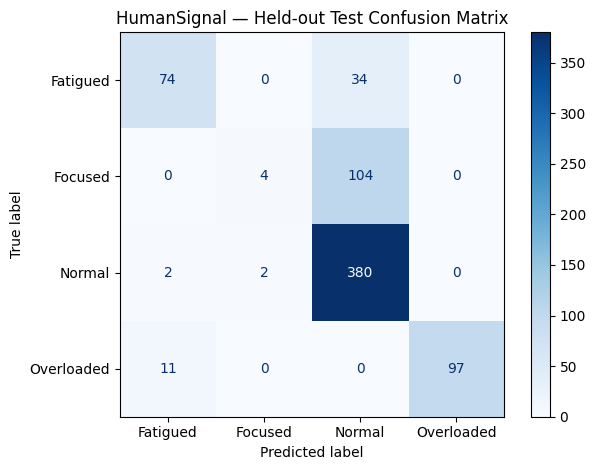


Saved predictions and evaluation metrics.


In [24]:

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    balanced_accuracy_score
)
from pathlib import Path

# 1. Load the saved model and held-out test set
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
OUTPUT_DIR = DATASETS_DIR

model_bundle = joblib.load(
    MODELS_DIR / "humansignal_random_forest.joblib"
)
rf_model = model_bundle["model"]
feature_columns = model_bundle["feature_columns"]

test_df = pd.read_csv(
    OUTPUT_DIR / "humansignal_test_set.csv"
)

X_test = test_df[feature_columns]
y_test = test_df["label"]

# 2. Predict
y_pred = rf_model.predict(X_test)

# 3. Overall metrics
print("Held-out test users:", model_bundle["test_users"])
print("Test rows:", len(test_df))
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1:           {f1_score(y_test, y_pred, average='macro'):.4f}")

# 4. Per-class precision, recall, and F1
print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=rf_model.classes_,
        zero_division=0,
        digits=4
    )
)

# 5. Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=rf_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_model.classes_
)
disp.plot(cmap="Blues", values_format="d")
plt.title("HumanSignal — Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()

# 6. Save predictions and metrics
results_df = test_df[
    ["user_id", "session_id", "window_start", "label"]
].copy()

results_df["predicted_label"] = y_pred
results_df["correct"] = results_df["label"] == results_df["predicted_label"]

results_df.to_csv(
    OUTPUT_DIR / "humansignal_test_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame({
    "metric": ["accuracy", "balanced_accuracy", "macro_f1"],
    "value": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        f1_score(y_test, y_pred, average="macro")
    ]
})

metrics_df.to_csv(
    OUTPUT_DIR / "humansignal_evaluation_metrics.csv",
    index=False
)

print("\nSaved predictions and evaluation metrics.")


In [25]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": model_bundle["feature_columns"],
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 20 features used by the Random Forest:")
display(importance_df.head(20).reset_index(drop=True).round(5))


Top 20 features used by the Random Forest:


,feature,importance
0,mean_rt_ms_z,0.09496
1,std_rt_ms_z,0.09281
2,mouse_jitter_z,0.07451
3,std_iki_ms_z,0.06681
4,std_rt_ms_roll_mean_30s,0.06465
5,mean_iki_ms_z,0.05439
6,mouse_jitter_roll_mean_30s,0.04680
7,std_iki_ms,0.04648
8,std_rt_ms,0.04412
9,mouse_speed_mean_roll_mean_30s,0.03420


In [26]:

# Compare raw and normalized features for Focused vs Normal
comparison_features = [
    "mean_rt_ms_z",
    "std_rt_ms_z",
    "mean_iki_ms_z",
    "mouse_jitter_z",
    "keys_per_sec_z",
    "error_rate_z",
    "mean_rt_ms_roll_mean_30s",
    "std_rt_ms_roll_mean_30s",
    "mouse_jitter_roll_mean_30s"
]

focused_normal = df_ml[
    df_ml["label"].isin(["Focused", "Normal"])
].copy()

comparison = (
    focused_normal.groupby("label")[comparison_features]
    .agg(["mean", "std"])
    .T
)

display(comparison.round(4))

print("\nMean difference: Focused minus Normal")
mean_difference = (
    focused_normal.groupby("label")[comparison_features]
    .mean()
    .T
)

mean_difference["Focused_minus_Normal"] = (
    mean_difference["Focused"] - mean_difference["Normal"]
)

display(
    mean_difference[["Focused_minus_Normal"]]
    .sort_values(
        "Focused_minus_Normal",
        key=lambda s: s.abs(),
        ascending=False
    )
    .round(4)
)


label                             Focused    Normal
mean_rt_ms_z               mean   -0.8466    0.0393
                           std     1.1478    1.0605
std_rt_ms_z                mean   -1.2822   -0.0143
                           std     1.0543    1.0285
mean_iki_ms_z              mean   -1.5210    0.0633
                           std     1.3062    1.0056
mouse_jitter_z             mean   -0.8748   -0.0143
                           std     1.1760    1.0595
keys_per_sec_z             mean    1.2434   -0.0401
                           std     1.4059    1.0263
error_rate_z               mean   -0.2270    0.0460
                           std     0.9650    1.0810
mean_rt_ms_roll_mean_30s   mean  252.4363  266.6818
                           std    33.1849   33.8413
std_rt_ms_roll_mean_30s    mean   38.9913   45.1157
                           std     6.8153    7.1850
mouse_jitter_roll_mean_30s mean    1.8091    1.9469
                           std     0.2682    0.3018


Mean difference: Focused minus Normal


label,Focused_minus_Normal
mean_rt_ms_roll_mean_30s,-14.2454
std_rt_ms_roll_mean_30s,-6.1244
mean_iki_ms_z,-1.5843
keys_per_sec_z,1.2835
std_rt_ms_z,-1.2679
mean_rt_ms_z,-0.8859
mouse_jitter_z,-0.8605
error_rate_z,-0.2730
mouse_jitter_roll_mean_30s,-0.1378


In [27]:

# Inspect the held-out Focused samples and their predicted probabilities

probabilities = rf_model.predict_proba(X_test)

probability_df = pd.DataFrame(
    probabilities,
    columns=rf_model.classes_,
    index=X_test.index
)

focused_mask = y_test.eq("Focused")

focused_results = pd.DataFrame({
    "user_id": test_df.loc[focused_mask, "user_id"],
    "session_id": test_df.loc[focused_mask, "session_id"],
    "window_start": test_df.loc[focused_mask, "window_start"],
    "actual": y_test.loc[focused_mask],
    "predicted": pd.Series(y_pred, index=y_test.index).loc[focused_mask],
    "p_focused": probability_df.loc[focused_mask, "Focused"],
    "p_normal": probability_df.loc[focused_mask, "Normal"],
    "p_fatigued": probability_df.loc[focused_mask, "Fatigued"],
    "p_overloaded": probability_df.loc[focused_mask, "Overloaded"]
})

print("Focused test samples:", len(focused_results))
print(
    "Correctly classified:",
    (focused_results["predicted"] == "Focused").sum()
)

print("\nAverage predicted probabilities for actual Focused samples:")
display(
    focused_results[
        ["p_focused", "p_normal", "p_fatigued", "p_overloaded"]
    ].mean().round(4).to_frame("mean_probability")
)

print("\n10 Focused samples most strongly predicted as Normal:")
display(
    focused_results[
        focused_results["predicted"] == "Normal"
    ]
    .sort_values("p_normal", ascending=False)
    .head(10)
    .round(4)
    .reset_index(drop=True)
)


Focused test samples: 108
Correctly classified: 4

Average predicted probabilities for actual Focused samples:


,mean_probability
p_focused,0.3402
p_normal,0.6319
p_fatigued,0.0242
p_overloaded,0.0037



10 Focused samples most strongly predicted as Normal:


,user_id,session_id,window_start,actual,predicted,p_focused,p_normal,p_fatigued,p_overloaded
0,U10,S038,115,Focused,Normal,0.0676,0.8802,0.0522,0.0000
1,U10,S038,120,Focused,Normal,0.0828,0.8607,0.0566,0.0000
2,U11,S042,140,Focused,Normal,0.1020,0.8277,0.0583,0.0120
3,U10,S038,125,Focused,Normal,0.1607,0.8094,0.0272,0.0026
4,U11,S042,145,Focused,Normal,0.1390,0.8034,0.0497,0.0080
5,U10,S038,135,Focused,Normal,0.1842,0.7965,0.0193,0.0000
6,U11,S042,135,Focused,Normal,0.0729,0.7801,0.0935,0.0535
7,U10,S038,140,Focused,Normal,0.2214,0.7717,0.0069,0.0000
8,U11,S042,260,Focused,Normal,0.2096,0.7649,0.0255,0.0000
9,U11,S042,150,Focused,Normal,0.1460,0.7644,0.0793,0.0102


In [28]:

from sklearn.metrics import accuracy_score, f1_score, recall_score

user_results = []

for user_id in sorted(test_df["user_id"].unique()):
    mask = test_df["user_id"].eq(user_id)

    actual = y_test.loc[mask]
    predicted = pd.Series(y_pred, index=y_test.index).loc[mask]

    user_results.append({
        "user_id": user_id,
        "samples": int(mask.sum()),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual,
            predicted,
            labels=rf_model.classes_,
            average="macro",
            zero_division=0
        ),
        "focused_recall": recall_score(
            actual,
            predicted,
            labels=["Focused"],
            average=None,
            zero_division=0
        )[0]
    })

user_results_df = pd.DataFrame(user_results)

display(
    user_results_df
    .sort_values("user_id")
    .round(4)
    .reset_index(drop=True)
)


,user_id,samples,accuracy,macro_f1,focused_recall
0,U01,236,0.8136,0.6993,0.0556
1,U10,236,0.7458,0.6073,0.0556
2,U11,236,0.7924,0.6552,0.0000


In [29]:

# Compare Focused and Normal feature distributions per held-out user

features_to_check = [
    "mean_rt_ms",
    "std_rt_ms",
    "mean_iki_ms",
    "keys_per_sec",
    "mouse_jitter",
    "error_rate",
    "std_rt_ms_z",
    "mean_rt_ms_z"
]

test_users_df = df_ml[
    df_ml["user_id"].isin(model_bundle["test_users"])
].copy()

user_class_summary = (
    test_users_df[
        test_users_df["label"].isin(["Focused", "Normal"])
    ]
    .groupby(["user_id", "label"])[features_to_check]
    .mean()
    .round(3)
)

display(user_class_summary)

# Calculate Focused minus Normal mean for each user
focused_normal_means = (
    test_users_df[
        test_users_df["label"].isin(["Focused", "Normal"])
    ]
    .groupby(["user_id", "label"])[features_to_check]
    .mean()
)

differences = []

for user_id in model_bundle["test_users"]:
    try:
        focused = focused_normal_means.loc[(user_id, "Focused")]
        normal = focused_normal_means.loc[(user_id, "Normal")]

        for feature in features_to_check:
            differences.append({
                "user_id": user_id,
                "feature": feature,
                "focused_minus_normal": focused[feature] - normal[feature]
            })
    except KeyError:
        print(f"Missing Focused or Normal samples for {user_id}")

differences_df = pd.DataFrame(differences)

display(
    differences_df.pivot(
        index="feature",
        columns="user_id",
        values="focused_minus_normal"
    ).round(3)
)


mean_rt_ms  std_rt_ms  mean_iki_ms  keys_per_sec  \
user_id label                                                       
U01     Focused     259.831     32.419      194.922         5.003   
        Normal      266.784     36.498      209.209         4.566   
U10     Focused     262.758     41.164      174.700         5.751   
        Normal      284.548     45.778      185.788         5.182   
U11     Focused     233.639     51.433      186.644         5.313   
        Normal      249.519     57.360      203.378         4.711   

                 mouse_jitter  error_rate  std_rt_ms_z  mean_rt_ms_z  
user_id label                                                         
U01     Focused         1.791       0.019       -0.278        -0.057  
        Normal          1.839       0.034       -0.214        -0.073  
U10     Focused         1.540       0.014       -1.566        -1.358  
        Normal          1.580       0.021       -0.035        -0.138  
U11     Focused         1.836       0.020       -1.662        -0.464  
        Normal          1.843       0.024       -0.016         0.345

user_id,U01,U10,U11
feature,,,
error_rate,-0.015,-0.007,-0.003
keys_per_sec,0.437,0.569,0.602
mean_iki_ms,-14.286,-11.088,-16.734
mean_rt_ms,-6.954,-21.789,-15.880
mean_rt_ms_z,0.017,-1.220,-0.809
mouse_jitter,-0.049,-0.040,-0.007
std_rt_ms,-4.079,-4.614,-5.927
std_rt_ms_z,-0.065,-1.531,-1.646


In [30]:

# Compare Focused and Normal feature patterns in training users

train_df = df_ml[
    df_ml["user_id"].isin(model_bundle["train_users"]) &
    df_ml["label"].isin(["Focused", "Normal"])
].copy()

features_to_check = [
    "mean_rt_ms",
    "std_rt_ms",
    "mean_iki_ms",
    "keys_per_sec",
    "mouse_jitter",
    "error_rate",
    "mean_rt_ms_z",
    "std_rt_ms_z"
]

train_means = train_df.groupby("label")[features_to_check].mean().T
train_means["Focused_minus_Normal"] = (
    train_means["Focused"] - train_means["Normal"]
)

print("Training users:", model_bundle["train_users"])
print("\nTraining-set class means:")
display(train_means.round(4))

print("\nHeld-out users' class differences:")
display(
    differences_df.pivot(
        index="feature",
        columns="user_id",
        values="focused_minus_normal"
    ).round(4)
)


Training users: ['U02', 'U03', 'U04', 'U05', 'U06', 'U07', 'U08', 'U09', 'U12']

Training-set class means:


label,Focused,Normal,Focused_minus_Normal
mean_rt_ms,249.9182,266.7675,-16.8493
std_rt_ms,37.6164,44.7605,-7.1441
mean_iki_ms,171.2772,184.3803,-13.1031
keys_per_sec,5.7777,5.2374,0.5402
mouse_jitter,1.8202,2.0178,-0.1976
error_rate,0.0167,0.0225,-0.0058
mean_rt_ms_z,-0.9200,0.0376,-0.9576
std_rt_ms_z,-1.3201,0.0103,-1.3304



Held-out users' class differences:


user_id,U01,U10,U11
feature,,,
error_rate,-0.0153,-0.0073,-0.0035
keys_per_sec,0.4370,0.5688,0.6015
mean_iki_ms,-14.2864,-11.0883,-16.7337
mean_rt_ms,-6.9538,-21.7893,-15.8799
mean_rt_ms_z,0.0167,-1.2202,-0.8093
mouse_jitter,-0.0486,-0.0401,-0.0074
std_rt_ms,-4.0790,-4.6142,-5.9268
std_rt_ms_z,-0.0646,-1.5308,-1.6457


In [31]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# Load the existing train/test split
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
OUTPUT_DIR = DATASETS_DIR

df_ml = pd.read_csv(DATA_PATH)
model_bundle = joblib.load(
    MODELS_DIR / "humansignal_random_forest.joblib"
)

feature_columns = model_bundle["feature_columns"]
train_users = model_bundle["train_users"]
test_users = model_bundle["test_users"]

train_mask = df_ml["user_id"].isin(train_users)
test_mask = df_ml["user_id"].isin(test_users)

X_train = df_ml.loc[train_mask, feature_columns]
y_train = df_ml.loc[train_mask, "label"]

X_test = df_ml.loc[test_mask, feature_columns]
y_test = df_ml.loc[test_mask, "label"]

assert set(train_users).isdisjoint(set(test_users))

# Current Random Forest baseline
rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# Alternative tree-based model
et = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
et.fit(X_train, y_train)
et_pred = et.predict(X_test)

# Compare results
comparison = pd.DataFrame([
    {
        "model": "Random Forest",
        "accuracy": accuracy_score(y_test, rf_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, rf_pred),
        "macro_f1": f1_score(
            y_test, rf_pred, average="macro", zero_division=0
        ),
        "focused_recall": classification_report(
            y_test, rf_pred, output_dict=True, zero_division=0
        )["Focused"]["recall"]
    },
    {
        "model": "Extra Trees",
        "accuracy": accuracy_score(y_test, et_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, et_pred),
        "macro_f1": f1_score(
            y_test, et_pred, average="macro", zero_division=0
        ),
        "focused_recall": classification_report(
            y_test, et_pred, output_dict=True, zero_division=0
        )["Focused"]["recall"]
    }
])

display(comparison.round(4))

print("\nExtra Trees classification report:")
print(classification_report(y_test, et_pred, zero_division=0))

print("Extra Trees confusion matrix:")
print(confusion_matrix(y_test, et_pred, labels=et.classes_))


,model,accuracy,balanced_accuracy,macro_f1,focused_recall
0,Random Forest,0.7839,0.6525,0.6545,0.0370
1,Extra Trees,0.8432,0.7480,0.7945,0.4259



Extra Trees classification report:
              precision    recall  f1-score   support

    Fatigued       0.86      0.67      0.75       108
     Focused       0.98      0.43      0.59       108
      Normal       0.80      0.99      0.88       384
  Overloaded       1.00      0.91      0.95       108

    accuracy                           0.84       708
   macro avg       0.91      0.75      0.79       708
weighted avg       0.86      0.84      0.83       708

Extra Trees confusion matrix:
[[ 72   0  36   0]
 [  0  46  62   0]
 [  2   1 381   0]
 [ 10   0   0  98]]


In [32]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
import pandas as pd

# Reuse X_train, X_test, y_train and y_test from Cell 25
# Keep the same held-out users.

weight_settings = {
    "balanced": {
        "Fatigued": 1,
        "Focused": 1,
        "Normal": 1,
        "Overloaded": 1
    },
    "focused_x2": {
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    "focused_x3": {
        "Fatigued": 1,
        "Focused": 3,
        "Normal": 1,
        "Overloaded": 1
    }
}

comparison_rows = []
candidate_models = {}

for setting_name, weights in weight_settings.items():
    model = ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight=weights,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    candidate_models[setting_name] = model

    comparison_rows.append({
        "setting": setting_name,
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_f1": f1_score(
            y_test, predictions,
            average="macro",
            zero_division=0
        ),
        "focused_precision": report["Focused"]["precision"],
        "focused_recall": report["Focused"]["recall"],
        "focused_f1": report["Focused"]["f1-score"],
        "normal_recall": report["Normal"]["recall"]
    })

weight_comparison = pd.DataFrame(comparison_rows)

display(
    weight_comparison
    .sort_values("macro_f1", ascending=False)
    .round(4)
    .reset_index(drop=True)
)


,setting,accuracy,balanced_accuracy,macro_f1,focused_precision,focused_recall,focused_f1,normal_recall
0,focused_x2,0.8503,0.7563,0.8067,0.9815,0.4907,0.6543,0.9974
1,focused_x3,0.8432,0.7447,0.7949,0.9800,0.4537,0.6203,0.9974
2,balanced,0.8376,0.7371,0.7859,0.9787,0.4259,0.5935,0.9948


Dataset shape: (2832, 57)
Features: 52
Classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']

Training users: ['U02', 'U03', 'U04', 'U05', 'U06', 'U07', 'U08', 'U09', 'U12']
Held-out users: ['U01', 'U10', 'U11']
Training rows: 2124
Test rows: 708

Model training completed.

Accuracy:          0.8503
Balanced accuracy: 0.7563
Macro F1:           0.8067

Classification report:
              precision    recall  f1-score   support

    Fatigued       0.88      0.62      0.73       108
     Focused       0.98      0.49      0.65       108
      Normal       0.80      1.00      0.89       384
  Overloaded       1.00      0.92      0.96       108

    accuracy                           0.85       708
   macro avg       0.92      0.76      0.81       708
weighted avg       0.87      0.85      0.84       708



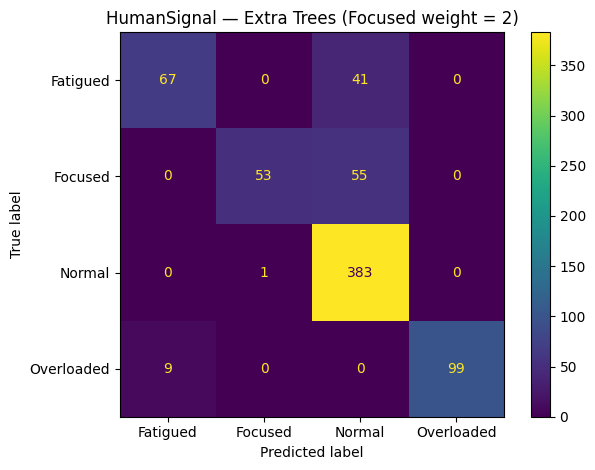


Saved model: d:\HumanSignal\AI\Models\humansignal_final_candidate.joblib
Saved predictions.
Saved metrics.

Training pipeline completed successfully.


In [33]:

import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# =====================================================
# 1. Load the validated temporal dataset
# =====================================================
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
OUTPUT_DIR = DATASETS_DIR

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

df_ml = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_ml.shape)

# =====================================================
# 2. Define features and target
# =====================================================
excluded_columns = [
    "user_id",
    "session_id",
    "window_start",
    "is_baseline",
    "label"
]

feature_columns = [
    col for col in df_ml.columns
    if col not in excluded_columns
]

X = df_ml[feature_columns].copy()
y = df_ml["label"].copy()

assert X.select_dtypes(exclude=[np.number]).empty
assert np.isfinite(X.to_numpy(dtype=float)).all()
assert y.notna().all()

print("Features:", len(feature_columns))
print("Classes:", sorted(y.unique()))

# =====================================================
# 3. Preserve the existing user-level split
# =====================================================
# These are the held-out users used in your previous
# model comparisons. Do not train on these users.
test_users = ["U01", "U10", "U11"]

available_users = set(df_ml["user_id"].unique())
assert set(test_users).issubset(available_users)

test_mask = df_ml["user_id"].isin(test_users)
train_mask = ~test_mask

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

train_users = sorted(df_ml.loc[train_mask, "user_id"].unique())

assert set(train_users).isdisjoint(test_users)

expected_classes = {
    "Normal", "Focused", "Fatigued", "Overloaded"
}
assert set(y_train.unique()) == expected_classes

print("\nTraining users:", train_users)
print("Held-out users:", test_users)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

# =====================================================
# 4. Train Extra Trees with Focused class weight = 2
# =====================================================
model = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight={
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nModel training completed.")

# =====================================================
# 5. Evaluate on held-out users
# =====================================================
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print(f"\nAccuracy:          {accuracy:.4f}")
print(f"Balanced accuracy: {balanced_acc:.4f}")
print(f"Macro F1:           {macro_f1:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)
disp.plot(values_format="d")
plt.title("HumanSignal — Extra Trees (Focused weight = 2)")
plt.tight_layout()
plt.show()

# =====================================================
# 6. Save model and evaluation outputs
# =====================================================
model_bundle = {
    "model": model,
    "feature_columns": feature_columns,
    "classes": list(model.classes_),
    "train_users": train_users,
    "test_users": test_users,
    "class_weight": {
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    "random_state": 42
}

model_path = MODELS_DIR / "humansignal_final_candidate.joblib"
joblib.dump(model_bundle, model_path)

predictions_df = df_ml.loc[
    test_mask,
    ["user_id", "session_id", "window_start", "label"]
].copy()

predictions_df["predicted_label"] = y_pred
predictions_df["correct"] = (
    predictions_df["label"] == predictions_df["predicted_label"]
)

predictions_df.to_csv(
    OUTPUT_DIR / "humansignal_final_candidate_predictions.csv",
    index=False
)

metrics_df = pd.DataFrame([{
    "model": "ExtraTrees_Focused_x2",
    "accuracy": accuracy,
    "balanced_accuracy": balanced_acc,
    "macro_f1": macro_f1,
    "train_users": len(train_users),
    "test_users": len(test_users)
}])

metrics_df.to_csv(
    OUTPUT_DIR / "humansignal_final_candidate_metrics.csv",
    index=False
)

print("\nSaved model:", model_path)
print("Saved predictions.")
print("Saved metrics.")
print("\nTraining pipeline completed successfully.")


In [34]:
from pathlib import Path

print("Working directory:", Path.cwd())
print("Datasets folder:", DATASETS_DIR.resolve())
print("Models folder:", MODELS_DIR.resolve())

checks = {
    "Original dataset": DATASETS_DIR / "humansignal_dataset.csv",
    "Temporal dataset": DATASETS_DIR / "humansignal_dataset_temporal.csv",
    "Random Forest model": MODELS_DIR / "humansignal_random_forest.joblib",
    "Final candidate model": MODELS_DIR / "humansignal_final_candidate.joblib",
    "Final metrics": DATASETS_DIR / "humansignal_final_candidate_metrics.csv",
    "Final predictions": DATASETS_DIR / "humansignal_final_candidate_predictions.csv",
}

for name, path in checks.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")
    print(f"  {path.resolve()}")


Working directory: d:\HumanSignal\AI\Notebooks
Datasets folder: D:\HumanSignal\AI\Datasets
Models folder: D:\HumanSignal\AI\Models
Original dataset: FOUND
  D:\HumanSignal\AI\Datasets\humansignal_dataset.csv
Temporal dataset: FOUND
  D:\HumanSignal\AI\Datasets\humansignal_dataset_temporal.csv
Random Forest model: FOUND
  D:\HumanSignal\AI\Models\humansignal_random_forest.joblib
Final candidate model: FOUND
  D:\HumanSignal\AI\Models\humansignal_final_candidate.joblib
Final metrics: FOUND
  D:\HumanSignal\AI\Datasets\humansignal_final_candidate_metrics.csv
Final predictions: FOUND
  D:\HumanSignal\AI\Datasets\humansignal_final_candidate_predictions.csv


In [35]:
import pandas as pd
import numpy as np

# Load the exact dataset used by the current model
audit_path = DATASETS_DIR / "humansignal_dataset_temporal.csv"
audit_df = pd.read_csv(audit_path)

required = {
    "user_id", "session_id", "window_start",
    "is_baseline", "label"
}
missing = required - set(audit_df.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

print("DATASET AUDIT")
print("=" * 60)
print("Shape:", audit_df.shape)
print("Users:", audit_df["user_id"].nunique())
print("Sessions:", audit_df[["user_id", "session_id"]]
      .drop_duplicates().shape[0])

# 1. Check labels in baseline vs non-baseline windows
print("\n1. LABEL DISTRIBUTION BY BASELINE STATUS")
baseline_table = pd.crosstab(
    audit_df["is_baseline"],
    audit_df["label"],
    normalize="index"
).mul(100).round(2)

display(baseline_table)

baseline_counts = pd.crosstab(
    audit_df["is_baseline"], audit_df["label"]
)
display(baseline_counts)

baseline_table.to_csv(
    DATASETS_DIR / "humansignal_baseline_label_audit.csv"
)

# 2. Check whether sessions contain multiple labels
session_labels = (
    audit_df.groupby(["user_id", "session_id"])
    .agg(
        rows=("label", "size"),
        distinct_labels=("label", "nunique"),
        labels=("label", lambda s: ", ".join(sorted(s.unique()))),
        baseline_rows=("is_baseline", "sum")
    )
    .reset_index()
)

print("\n2. SESSION LABEL CONSISTENCY")
print("Sessions with multiple labels:",
      int((session_labels["distinct_labels"] > 1).sum()))
display(
    session_labels[
        session_labels["distinct_labels"] > 1
    ].head(20)
)

session_labels.to_csv(
    DATASETS_DIR / "humansignal_session_label_audit.csv",
    index=False
)

# 3. Compare Focused vs Normal feature patterns
compare_classes = audit_df[
    audit_df["label"].isin(["Focused", "Normal"])
].copy()

candidate_features = [
    "mean_rt_ms_z",
    "std_rt_ms_z",
    "mean_iki_ms_z",
    "keys_per_sec_z",
    "mouse_jitter_z",
    "error_rate_z",
    "mean_rt_ms_roll_mean_30s",
    "std_rt_ms_roll_mean_30s",
    "mouse_jitter_roll_mean_30s",
]

features = [
    col for col in candidate_features
    if col in compare_classes.columns
]

if not features:
    raise ValueError("No expected comparison features were found.")

class_summary = (
    compare_classes.groupby("label")[features]
    .agg(["mean", "std"])
    .T
)

print("\n3. FOCUSED VS NORMAL FEATURE SUMMARY")
display(class_summary.round(4))

class_means = compare_classes.groupby("label")[features].mean()
mean_difference = (
    class_means.loc["Focused"] - class_means.loc["Normal"]
)

# Standardized mean difference (Cohen's d, pooled SD)
focused = compare_classes.loc[
    compare_classes["label"] == "Focused", features
]
normal = compare_classes.loc[
    compare_classes["label"] == "Normal", features
]

pooled_sd = np.sqrt(
    (
        (len(focused) - 1) * focused.var(ddof=1)
        + (len(normal) - 1) * normal.var(ddof=1)
    ) / max(len(focused) + len(normal) - 2, 1)
)

effect_size = (focused.mean() - normal.mean()) / pooled_sd.replace(0, np.nan)

feature_audit = pd.DataFrame({
    "focused_mean": focused.mean(),
    "normal_mean": normal.mean(),
    "focused_minus_normal": mean_difference,
    "standardized_difference": effect_size
}).sort_values(
    "standardized_difference",
    key=lambda s: s.abs(),
    ascending=False
)

display(feature_audit.round(4))

feature_audit.to_csv(
    DATASETS_DIR / "humansignal_focused_normal_feature_audit.csv"
)

# 4. Report potential baseline-label concern
print("\n4. INTERPRETATION CHECK")

if "Normal" in baseline_counts.columns and 1 in baseline_counts.index:
    normal_baseline_pct = (
        baseline_counts.loc[1, "Normal"]
        / baseline_counts.loc[1].sum() * 100
    )
    print(f"Baseline windows labeled Normal: {normal_baseline_pct:.2f}%")

print(
    "\nAudit complete. No dataset or model was modified.\n"
    "Reports saved in:", DATASETS_DIR.resolve()
)


DATASET AUDIT
Shape: (2832, 57)
Users: 12
Sessions: 48

1. LABEL DISTRIBUTION BY BASELINE STATUS


label,Fatigued,Focused,Normal,Overloaded
is_baseline,,,,
0,25.0,25.0,25.0,25.0
1,0.0,0.0,100.0,0.0


label,Fatigued,Focused,Normal,Overloaded
is_baseline,,,,
0,432,432,432,432
1,0,0,1104,0



2. SESSION LABEL CONSISTENCY
Sessions with multiple labels: 36


,user_id,session_id,rows,distinct_labels,labels,baseline_rows
1,U01,S002,59,2,"Focused, Normal",23
2,U01,S003,59,2,"Fatigued, Normal",23
3,U01,S004,59,2,"Normal, Overloaded",23
5,U02,S006,59,2,"Focused, Normal",23
6,U02,S007,59,2,"Fatigued, Normal",23
7,U02,S008,59,2,"Normal, Overloaded",23
9,U03,S010,59,2,"Focused, Normal",23
10,U03,S011,59,2,"Fatigued, Normal",23
11,U03,S012,59,2,"Normal, Overloaded",23
13,U04,S014,59,2,"Focused, Normal",23



3. FOCUSED VS NORMAL FEATURE SUMMARY


label                             Focused    Normal
mean_rt_ms_z               mean   -0.8466    0.0393
                           std     1.1478    1.0605
std_rt_ms_z                mean   -1.2822   -0.0143
                           std     1.0543    1.0285
mean_iki_ms_z              mean   -1.5210    0.0633
                           std     1.3062    1.0056
keys_per_sec_z             mean    1.2434   -0.0401
                           std     1.4059    1.0263
mouse_jitter_z             mean   -0.8748   -0.0143
                           std     1.1760    1.0595
error_rate_z               mean   -0.2270    0.0460
                           std     0.9650    1.0810
mean_rt_ms_roll_mean_30s   mean  252.4363  266.6818
                           std    33.1849   33.8413
std_rt_ms_roll_mean_30s    mean   38.9913   45.1157
                           std     6.8153    7.1850
mouse_jitter_roll_mean_30s mean    1.8091    1.9469
                           std     0.2682    0.3018

,focused_mean,normal_mean,focused_minus_normal,standardized_difference
mean_iki_ms_z,-1.5210,0.0633,-1.5843,-1.4687
std_rt_ms_z,-1.2822,-0.0143,-1.2679,-1.2259
keys_per_sec_z,1.2434,-0.0401,1.2835,1.1454
std_rt_ms_roll_mean_30s,38.9913,45.1157,-6.1244,-0.8619
mean_rt_ms_z,-0.8466,0.0393,-0.8859,-0.8201
mouse_jitter_z,-0.8748,-0.0143,-0.8605,-0.7922
mouse_jitter_roll_mean_30s,1.8091,1.9469,-0.1378,-0.4676
mean_rt_ms_roll_mean_30s,252.4363,266.6818,-14.2454,-0.4227
error_rate_z,-0.2270,0.0460,-0.2730,-0.2584



4. INTERPRETATION CHECK
Baseline windows labeled Normal: 100.00%

Audit complete. No dataset or model was modified.
Reports saved in: D:\HumanSignal\AI\Datasets


In [36]:
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import GroupShuffleSplit

# --------------------------------------------------
# 1. Load dataset
# --------------------------------------------------
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
df_exp = pd.read_csv(DATA_PATH)

TARGET = "label"
GROUP = "user_id"

# Same held-out users as the previous experiment
test_users = ["U01", "U10", "U11"]

exclude_cols = {
    "user_id", "session_id", "window_start",
    "is_baseline", "label"
}
feature_cols = [
    c for c in df_exp.columns if c not in exclude_cols
]

# Validate features
if df_exp[feature_cols].isna().any().any():
    raise ValueError("Missing feature values detected.")

if not np.isfinite(df_exp[feature_cols].to_numpy(dtype=float)).all():
    raise ValueError("Non-finite feature values detected.")

train_all = df_exp[~df_exp[GROUP].isin(test_users)].copy()
test_all = df_exp[df_exp[GROUP].isin(test_users)].copy()

if train_all.empty or test_all.empty:
    raise ValueError("Training or test split is empty.")

# --------------------------------------------------
# 2. Define both experiments
# --------------------------------------------------
experiments = {
    "All rows": (
        train_all.copy(),
        test_all.copy()
    ),
    "Exclude baseline": (
        train_all[train_all["is_baseline"] == 0].copy(),
        test_all[test_all["is_baseline"] == 0].copy()
    )
}

results = []
models = {}

for name, (train_df, test_df) in experiments.items():

    if train_df.empty or test_df.empty:
        raise ValueError(f"{name}: empty training or test data.")

    # Ensure both experiments use the same held-out users
    assert set(train_df[GROUP]).isdisjoint(set(test_df[GROUP]))

    X_train = train_df[feature_cols]
    y_train = train_df[TARGET]
    X_test = test_df[feature_cols]
    y_test = test_df[TARGET]

    model = ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight={
            "Fatigued": 1,
            "Focused": 2,
            "Normal": 1,
            "Overloaded": 1
        },
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    labels = ["Fatigued", "Focused", "Normal", "Overloaded"]

    results.append({
        "experiment": name,
        "train_rows": len(train_df),
        "test_rows": len(test_df),
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "macro_f1": f1_score(
            y_test, predictions,
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "focused_precision": classification_report(
            y_test, predictions,
            labels=labels,
            output_dict=True,
            zero_division=0
        )["Focused"]["precision"],
        "focused_recall": classification_report(
            y_test, predictions,
            labels=labels,
            output_dict=True,
            zero_division=0
        )["Focused"]["recall"],
        "focused_f1": classification_report(
            y_test, predictions,
            labels=labels,
            output_dict=True,
            zero_division=0
        )["Focused"]["f1-score"]
    })

    models[name] = model

    print(f"\n{'=' * 60}")
    print(name)
    print("Training rows:", len(train_df))
    print("Test rows:", len(test_df))
    print("\nClassification report:")
    print(classification_report(
        y_test, predictions,
        labels=labels,
        zero_division=0
    ))
    print("Confusion matrix (rows=true, columns=predicted):")
    print(pd.DataFrame(
        confusion_matrix(y_test, predictions, labels=labels),
        index=labels,
        columns=labels
    ))

# --------------------------------------------------
# 3. Compare and save results
# --------------------------------------------------
comparison = pd.DataFrame(results)
print("\nEXPERIMENT COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    DATASETS_DIR / "humansignal_baseline_experiment_comparison.csv",
    index=False
)

print("Comparison saved to:",
      DATASETS_DIR / "humansignal_baseline_experiment_comparison.csv")
print("Original dataset and existing models were not modified.")



All rows
Training rows: 2124
Test rows: 708

Classification report:
              precision    recall  f1-score   support

    Fatigued       0.88      0.62      0.73       108
     Focused       0.98      0.49      0.65       108
      Normal       0.80      1.00      0.89       384
  Overloaded       1.00      0.92      0.96       108

    accuracy                           0.85       708
   macro avg       0.92      0.76      0.81       708
weighted avg       0.87      0.85      0.84       708

Confusion matrix (rows=true, columns=predicted):
            Fatigued  Focused  Normal  Overloaded
Fatigued          67        0      41           0
Focused            0       53      55           0
Normal             0        1     383           0
Overloaded         9        0       0          99

Exclude baseline
Training rows: 1296
Test rows: 432

Classification report:
              precision    recall  f1-score   support

    Fatigued       0.85      0.76      0.80       108
     Focuse

,experiment,train_rows,test_rows,accuracy,balanced_accuracy,macro_f1,focused_precision,focused_recall,focused_f1
0,All rows,2124,708,0.8503,0.7563,0.8067,0.9815,0.4907,0.6543
1,Exclude baseline,1296,432,0.8056,0.8056,0.8097,0.7838,0.8056,0.7945


Comparison saved to: d:\HumanSignal\AI\Datasets\humansignal_baseline_experiment_comparison.csv
Original dataset and existing models were not modified.


In [37]:
import pandas as pd
import numpy as np

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# --------------------------------------------------
# 1. Load temporal dataset
# --------------------------------------------------
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
df_cv = pd.read_csv(DATA_PATH)

TEST_USERS = ["U01", "U10", "U11"]

# Reserve the previously held-out users from this experiment
train_users_df = df_cv[~df_cv["user_id"].isin(TEST_USERS)].copy()

# Evaluate only non-baseline rows for this experiment
df_cv = train_users_df[
    train_users_df["is_baseline"] == 0
].copy()

exclude_cols = {
    "user_id", "session_id", "window_start",
    "is_baseline", "label"
}
feature_cols = [
    col for col in df_cv.columns if col not in exclude_cols
]

X = df_cv[feature_cols]
y = df_cv["label"]
groups = df_cv["user_id"]

if groups.nunique() < 3:
    raise ValueError("Need at least 3 distinct training users.")

if X.isna().any().any():
    raise ValueError("Missing feature values found.")

if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Non-finite feature values found.")

print("Rows:", len(df_cv))
print("Training users:", sorted(groups.unique()))
print("Features:", len(feature_cols))
print("Class counts:")
print(y.value_counts())

# --------------------------------------------------
# 2. Group-based cross-validation
# --------------------------------------------------
cv = GroupKFold(n_splits=3)
labels = ["Fatigued", "Focused", "Normal", "Overloaded"]

fold_results = []
all_true = []
all_pred = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    train_groups = set(groups.iloc[train_idx])
    val_groups = set(groups.iloc[val_idx])

    assert train_groups.isdisjoint(val_groups)

    model = ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight={
            "Fatigued": 1,
            "Focused": 2,
            "Normal": 1,
            "Overloaded": 1
        },
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_val)

    all_true.extend(y_val.tolist())
    all_pred.extend(pred.tolist())

    report = classification_report(
        y_val,
        pred,
        labels=labels,
        output_dict=True,
        zero_division=0
    )

    fold_results.append({
        "fold": fold,
        "validation_users": ", ".join(sorted(val_groups)),
        "accuracy": accuracy_score(y_val, pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, pred),
        "macro_f1": f1_score(
            y_val, pred, labels=labels,
            average="macro", zero_division=0
        ),
        "focused_recall": report["Focused"]["recall"],
        "focused_f1": report["Focused"]["f1-score"]
    })

# --------------------------------------------------
# 3. Report fold-by-fold and combined performance
# --------------------------------------------------
fold_df = pd.DataFrame(fold_results)

print("\nFOLD RESULTS")
display(fold_df.round(4))

print("\nMEAN CROSS-VALIDATION METRICS")
display(
    fold_df[
        ["accuracy", "balanced_accuracy", "macro_f1",
         "focused_recall", "focused_f1"]
    ].mean().to_frame("mean").round(4)
)

print("\nCOMBINED OUT-OF-FOLD CLASSIFICATION REPORT")
print(classification_report(
    all_true, all_pred,
    labels=labels,
    zero_division=0
))

fold_df.to_csv(
    DATASETS_DIR / "humansignal_baseline_excluded_cv.csv",
    index=False
)

print(
    "\nSaved report:",
    DATASETS_DIR / "humansignal_baseline_excluded_cv.csv"
)


Rows: 1296
Training users: ['U02', 'U03', 'U04', 'U05', 'U06', 'U07', 'U08', 'U09', 'U12']
Features: 52
Class counts:
label
Normal        324
Focused       324
Fatigued      324
Overloaded    324
Name: count, dtype: int64

FOLD RESULTS


,fold,validation_users,accuracy,balanced_accuracy,macro_f1,focused_recall,focused_f1
0,1,"U04, U07, U12",0.8495,0.8495,0.8506,0.9167,0.8182
1,2,"U03, U06, U09",0.8750,0.8750,0.8769,0.8611,0.8493
2,3,"U02, U05, U08",0.8796,0.8796,0.8799,0.8519,0.8762



MEAN CROSS-VALIDATION METRICS


,mean
accuracy,0.8681
balanced_accuracy,0.8681
macro_f1,0.8691
focused_recall,0.8765
focused_f1,0.8479



COMBINED OUT-OF-FOLD CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Fatigued       0.95      0.84      0.89       324
     Focused       0.82      0.88      0.85       324
      Normal       0.73      0.76      0.75       324
  Overloaded       0.99      1.00      1.00       324

    accuracy                           0.87      1296
   macro avg       0.87      0.87      0.87      1296
weighted avg       0.87      0.87      0.87      1296


Saved report: d:\HumanSignal\AI\Datasets\humansignal_baseline_excluded_cv.csv


In [38]:

import pandas as pd
import numpy as np

# ==========================================
# 1. Load data without modifying the original
# ==========================================
DATA_PATH = DATASETS_DIR / "humansignal_dataset_temporal.csv"
audit_df = pd.read_csv(DATA_PATH)

required_cols = {
    "user_id", "session_id", "is_baseline",
    "label", "window_start"
}
missing = required_cols - set(audit_df.columns)

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

print("=" * 65)
print("HUMANSIGNAL SYNTHETIC DATA AUDIT")
print("=" * 65)
print("Shape:", audit_df.shape)
print("Unique users:", audit_df["user_id"].nunique())
print("Unique sessions:", audit_df[["user_id", "session_id"]]
      .drop_duplicates().shape[0])
print("Missing values:", int(audit_df.isna().sum().sum()))
print("Duplicate rows:", int(audit_df.duplicated().sum()))

# ==========================================
# 2. Class distribution excluding baseline
# ==========================================
nonbaseline = audit_df[audit_df["is_baseline"] == 0].copy()

print("\n1. NON-BASELINE CLASS COUNTS")
display(nonbaseline["label"].value_counts().to_frame("rows"))

print("\nClass percentages:")
display(
    (nonbaseline["label"].value_counts(normalize=True) * 100)
    .round(2).to_frame("percent")
)

# ==========================================
# 3. Check labels within each session
# ==========================================
session_audit = (
    nonbaseline.groupby(["user_id", "session_id"])
    .agg(
        rows=("label", "size"),
        label_count=("label", "nunique"),
        labels=("label", lambda s: ", ".join(sorted(s.unique())))
    )
    .reset_index()
)

print("\n2. NON-BASELINE SESSION LABEL CONSISTENCY")
print("Sessions with multiple non-baseline labels:",
      int((session_audit["label_count"] > 1).sum()))
display(session_audit[session_audit["label_count"] > 1].head(20))

session_audit.to_csv(
    DATASETS_DIR / "humansignal_session_generation_audit.csv",
    index=False
)

# ==========================================
# 4. Class patterns in numeric features
# ==========================================
excluded = {
    "user_id", "session_id", "window_start",
    "is_baseline", "label"
}

features = [
    c for c in audit_df.columns
    if c not in excluded
    and pd.api.types.is_numeric_dtype(audit_df[c])
]

# Report non-finite values before computing statistics
finite_report = pd.DataFrame({
    "missing": audit_df[features].isna().sum(),
    "non_finite": [
        int((~np.isfinite(audit_df[c].dropna())).sum())
        for c in features
    ],
    "unique_values": audit_df[features].nunique()
})

print("\n3. FEATURE QUALITY ISSUES")
display(
    finite_report[
        (finite_report["missing"] > 0)
        | (finite_report["non_finite"] > 0)
        | (finite_report["unique_values"] <= 1)
    ]
)

# Exclude invalid features from summaries
valid_features = [
    c for c in features
    if audit_df[c].notna().all()
    and np.isfinite(audit_df[c].to_numpy(dtype=float)).all()
    and audit_df[c].nunique() > 1
]

# Focus on non-baseline rows for class comparison
class_means = nonbaseline.groupby("label")[valid_features].mean()
class_stds = nonbaseline.groupby("label")[valid_features].std()

print("\n4. MEAN FEATURE VALUES BY NON-BASELINE CLASS")
display(class_means.T.round(3))

class_means.to_csv(
    DATASETS_DIR / "humansignal_class_feature_means.csv"
)

# ==========================================
# 5. Focused vs Normal separability
# ==========================================
if {"Focused", "Normal"}.issubset(set(nonbaseline["label"].unique())):
    focused = nonbaseline.loc[
        nonbaseline["label"] == "Focused", valid_features
    ]
    normal = nonbaseline.loc[
        nonbaseline["label"] == "Normal", valid_features
    ]

    pooled_var = (
        (len(focused) - 1) * focused.var(ddof=1)
        + (len(normal) - 1) * normal.var(ddof=1)
    ) / max(len(focused) + len(normal) - 2, 1)

    pooled_sd = np.sqrt(pooled_var)
    difference = focused.mean() - normal.mean()

    effect_sizes = difference / pooled_sd.replace(0, np.nan)

    separability = pd.DataFrame({
        "focused_mean": focused.mean(),
        "normal_mean": normal.mean(),
        "mean_difference": difference,
        "standardized_difference": effect_sizes
    })

    separability["abs_effect"] = (
        separability["standardized_difference"].abs()
    )
    separability = separability.sort_values(
        "abs_effect", ascending=False
    )

    print("\n5. FEATURES WITH LARGEST FOCUSED/NORMAL DIFFERENCES")
    display(separability.head(20).round(4))

    separability.to_csv(
        DATASETS_DIR / "humansignal_focused_normal_separability.csv"
    )
else:
    print("Cannot compare Focused and Normal: one class is missing.")

# ==========================================
# 6. Label counts by user
# ==========================================
print("\n6. NON-BASELINE LABEL COUNTS BY USER")
user_labels = pd.crosstab(
    nonbaseline["user_id"], nonbaseline["label"]
)
display(user_labels)

user_labels.to_csv(
    DATASETS_DIR / "humansignal_user_label_distribution.csv"
)

print("\nAudit complete. Original data and models were not changed.")
print("Reports saved in:", DATASETS_DIR.resolve())


HUMANSIGNAL SYNTHETIC DATA AUDIT
Shape: (2832, 57)
Unique users: 12
Unique sessions: 48
Missing values: 0
Duplicate rows: 0

1. NON-BASELINE CLASS COUNTS


,rows
label,
Normal,432
Focused,432
Fatigued,432
Overloaded,432



Class percentages:


,percent
label,
Normal,25.0
Focused,25.0
Fatigued,25.0
Overloaded,25.0



2. NON-BASELINE SESSION LABEL CONSISTENCY
Sessions with multiple non-baseline labels: 0


...


5. FEATURES WITH LARGEST FOCUSED/NORMAL DIFFERENCES


,focused_mean,normal_mean,mean_difference,standardized_difference,abs_effect
mean_iki_ms_z,-1.5210,0.2252,-1.7462,-1.4703,1.4703
std_rt_ms_z,-1.2822,-0.0510,-1.2312,-1.1176,1.1176
keys_per_sec_z,1.2434,-0.1427,1.3861,1.0851,1.0851
std_iki_ms_z,-1.1092,0.1191,-1.2283,-1.0018,1.0018
std_rt_ms_roll_mean_30s,38.9913,45.2815,-6.2902,-0.9257,0.9257
std_rt_ms,38.6303,45.4113,-6.7810,-0.8943,0.8943
mean_rt_ms_z,-0.8466,0.1397,-0.9863,-0.8250,0.8250
keys_per_sec_roll_mean_30s,5.6356,5.1215,0.5141,0.7756,0.7756
mouse_speed_mean_z,0.6179,-0.1643,0.7822,0.7079,0.7079
error_rate_roll_mean_30s,0.0178,0.0253,-0.0075,-0.7058,0.7058



6. NON-BASELINE LABEL COUNTS BY USER


label,Fatigued,Focused,Normal,Overloaded
user_id,,,,
U01,36,36,36,36
U02,36,36,36,36
U03,36,36,36,36
U04,36,36,36,36
U05,36,36,36,36
U06,36,36,36,36
U07,36,36,36,36
U08,36,36,36,36
U09,36,36,36,36



Audit complete. Original data and models were not changed.
Reports saved in: D:\HumanSignal\AI\Datasets


In [39]:
# ============================================================
# CELL 39 — SYSTEMATIC MODEL & FEATURE COMPARISON
# ============================================================

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    recall_score,
    classification_report
)

# Load the temporal dataset
data_path = DATASETS_DIR / "humansignal_dataset_temporal.csv"
df = pd.read_csv(data_path)

# Exclude baseline windows for this experiment
df = df[df["is_baseline"] == 0].copy()

# Keep only the original training users.
# Previously held-out users are not used in this tuning experiment.
heldout_users = ["U01", "U10", "U11"]
df = df[~df["user_id"].isin(heldout_users)].copy()

# Define target, groups and numeric features
target = "label"
groups = df["user_id"]
y = df[target]

exclude_cols = {
    "label", "user_id", "session_id", "window_start",
    "is_baseline", "question_id"
}

feature_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

# Compare all features against a set without z-score features
feature_sets = {
    "All_features": feature_cols,
    "Without_z_features": [
        c for c in feature_cols if not c.endswith("_z")
    ]
}

models = {
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight={
            "Fatigued": 1,
            "Focused": 2,
            "Normal": 1,
            "Overloaded": 1
        },
        random_state=42,
        n_jobs=-1
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight={
            "Fatigued": 1,
            "Focused": 2,
            "Normal": 1,
            "Overloaded": 1
        },
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
}

cv = GroupKFold(n_splits=3)
results = []
oof_reports = {}

for feature_name, features in feature_sets.items():
    X = df[features].replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any():
        raise ValueError(
            f"Missing or infinite values found in {feature_name}. "
            "Fix them before comparing models."
        )

    for model_name, model_template in models.items():
        oof_predictions = np.empty(len(df), dtype=object)

        for fold, (train_idx, val_idx) in enumerate(
            cv.split(X, y, groups), start=1
        ):
            model = __import__("sklearn").base.clone(model_template)

            X_train = X.iloc[train_idx]
            y_train = y.iloc[train_idx]
            X_val = X.iloc[val_idx]
            y_val = y.iloc[val_idx]

            if model_name == "HistGradientBoosting":
                # Apply the same Focused-class emphasis using sample weights
                sample_weights = np.where(
                    y_train.to_numpy() == "Focused", 2.0, 1.0
                )
                model.fit(
                    X_train, y_train,
                    sample_weight=sample_weights
                )
            else:
                model.fit(X_train, y_train)

            oof_predictions[val_idx] = model.predict(X_val)

        results.append({
            "feature_set": feature_name,
            "model": model_name,
            "n_features": len(features),
            "accuracy": accuracy_score(y, oof_predictions),
            "balanced_accuracy": balanced_accuracy_score(
                y, oof_predictions
            ),
            "macro_f1": f1_score(
                y, oof_predictions, average="macro"
            ),
            "focused_recall": recall_score(
                y, oof_predictions,
                labels=["Focused"],
                average=None,
                zero_division=0
            )[0]
        })

        oof_reports[(feature_name, model_name)] = (
            y.to_numpy(), oof_predictions.copy()
        )

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
).reset_index(drop=True)

print("MODEL COMPARISON — 3-FOLD GROUP CROSS-VALIDATION")
display(results_df.round(4))

# Show the detailed classification report for the top configuration
best = results_df.iloc[0]
best_key = (best["feature_set"], best["model"])
true_labels, predicted_labels = oof_reports[best_key]

print("\nTOP CONFIGURATION")
print("Feature set:", best["feature_set"])
print("Model:", best["model"])
print("\nClassification report:")
print(classification_report(
    true_labels,
    predicted_labels,
    zero_division=0
))

# Confusion matrix for the best configuration
class_order = [
    "Fatigued",
    "Focused",
    "Normal",
    "Overloaded"
]

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=class_order
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in class_order],
    columns=[f"Predicted_{c}" for c in class_order]
)

print("\nConfusion Matrix:")
display(cm_df)

cm_path = DATASETS_DIR / "humansignal_confusion_matrix.csv"
cm_df.to_csv(cm_path)

print("Saved confusion matrix to:", cm_path)

# Save experiment results centrally
output_path = DATASETS_DIR / "humansignal_model_comparison.csv"
results_df.to_csv(output_path, index=False)

print("\nSaved comparison to:", output_path)


MODEL COMPARISON — 3-FOLD GROUP CROSS-VALIDATION


,feature_set,model,n_features,accuracy,balanced_accuracy,macro_f1,focused_recall
0,All_features,ExtraTrees,52,0.8681,0.8681,0.8690,0.8765
1,All_features,RandomForest,52,0.8056,0.8056,0.8082,0.7222
2,Without_z_features,ExtraTrees,41,0.7940,0.7940,0.7912,0.8272
3,Without_z_features,RandomForest,41,0.7670,0.7670,0.7673,0.7068
4,All_features,HistGradientBoosting,52,0.7361,0.7361,0.7298,0.7685
5,Without_z_features,HistGradientBoosting,41,0.7276,0.7276,0.7184,0.7685



TOP CONFIGURATION
Feature set: All_features
Model: ExtraTrees

Classification report:
              precision    recall  f1-score   support

    Fatigued       0.95      0.84      0.89       324
     Focused       0.82      0.88      0.85       324
      Normal       0.73      0.76      0.75       324
  Overloaded       0.99      1.00      1.00       324

    accuracy                           0.87      1296
   macro avg       0.87      0.87      0.87      1296
weighted avg       0.87      0.87      0.87      1296


Confusion Matrix:


,Predicted_Fatigued,Predicted_Focused,Predicted_Normal,Predicted_Overloaded
Actual_Fatigued,271,0,50,3
Actual_Focused,0,284,40,0
Actual_Normal,15,63,246,0
Actual_Overloaded,0,0,0,324


Saved confusion matrix to: d:\HumanSignal\AI\Datasets\humansignal_confusion_matrix.csv

Saved comparison to: d:\HumanSignal\AI\Datasets\humansignal_model_comparison.csv


In [40]:
# CELL 40 — Analyze feature differences between behavioral states

import pandas as pd
import numpy as np

data_path = DATASETS_DIR / "humansignal_dataset_temporal.csv"
df_analysis = pd.read_csv(data_path)

# Use non-baseline development users, matching Cell 39
df_analysis = df_analysis[
    (df_analysis["is_baseline"] == 0) &
    (~df_analysis["user_id"].isin(["U01", "U10", "U11"]))
].copy()

# Compare numeric feature means across labels
exclude_cols = {
    "label", "user_id", "session_id",
    "window_start", "is_baseline", "question_id"
}

numeric_features = [
    c for c in df_analysis.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

feature_means = df_analysis.groupby("label")[numeric_features].mean().T

print("Feature means by behavioral state:")
display(feature_means.round(3))

# Rank features by the difference between Focused and Normal
if "Focused" in feature_means.columns and "Normal" in feature_means.columns:
    feature_means["Focused_vs_Normal_abs_diff"] = (
        feature_means["Focused"] - feature_means["Normal"]
    ).abs()

    print("\nTop 15 features separating Focused and Normal by absolute mean difference:")
    display(
        feature_means[
            ["Focused", "Normal", "Focused_vs_Normal_abs_diff"]
        ]
        .sort_values("Focused_vs_Normal_abs_diff", ascending=False)
        .head(15)
        .round(3)
    )

Feature means by behavioral state:


label,Fatigued,Focused,Normal,Overloaded
mean_rt_ms,335.653,249.918,268.482,343.718
std_rt_ms,56.653,37.616,45.219,77.255
error_rate,0.048,0.017,0.025,0.053
mean_iki_ms,205.271,171.277,185.983,200.554
std_iki_ms,69.035,48.646,55.301,97.362
pause_count,0.870,0.213,0.318,0.858
max_pause_ms,954.222,260.083,374.460,945.148
keys_per_sec,4.307,5.778,5.198,4.434
mouse_speed_mean,386.763,447.660,422.258,497.135
mouse_jitter,2.162,1.820,2.033,3.004



Top 15 features separating Focused and Normal by absolute mean difference:


label,Focused,Normal,Focused_vs_Normal_abs_diff
max_pause_ms,260.083,374.460,114.377
max_pause_ms_roll_mean_30s,265.311,361.404,96.093
max_pause_ms_roll_std_30s,450.530,510.624,60.094
mouse_speed_mean,447.660,422.258,25.402
mouse_speed_mean_roll_mean_30s,446.765,422.743,24.022
mean_rt_ms,249.918,268.482,18.564
mean_rt_ms_roll_mean_30s,251.791,267.652,15.861
mean_iki_ms,171.277,185.983,14.706
mean_iki_ms_roll_mean_30s,172.081,185.793,13.712
std_rt_ms,37.616,45.219,7.603


In [41]:
# CELL 41 — Compare Focused vs Normal across users

import pandas as pd
import numpy as np

df_check = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df_check = df_check[
    (df_check["is_baseline"] == 0) &
    (~df_check["user_id"].isin(["U01", "U10", "U11"])) &
    (df_check["label"].isin(["Focused", "Normal"]))
].copy()

check_features = [
    "mean_rt_ms",
    "std_rt_ms",
    "mean_iki_ms",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "error_rate",
    "mouse_jitter"
]

# Calculate each user's average for each state
user_means = df_check.groupby(
    ["user_id", "label"]
)[check_features].mean().unstack("label")

# Calculate Focused minus Normal for each user
differences = pd.DataFrame(index=user_means.index)

for feature in check_features:
    differences[feature] = (
        user_means[(feature, "Focused")] -
        user_means[(feature, "Normal")]
    )

print("Focused minus Normal mean differences by user:")
display(differences.round(3))

print("\nDirection of difference across users:")
direction_summary = pd.DataFrame({
    "users_with_lower_focused_value": (differences < 0).sum(),
    "users_with_higher_focused_value": (differences > 0).sum(),
    "users_with_equal_values": (differences == 0).sum()
})

display(direction_summary)

Focused minus Normal mean differences by user:


,mean_rt_ms,std_rt_ms,mean_iki_ms,max_pause_ms,keys_per_sec,mouse_speed_mean,error_rate,mouse_jitter
user_id,,,,,,,,
U02,-23.814,-7.058,-17.989,-47.778,0.482,45.983,-0.016,-0.224
U03,-19.506,-9.233,-14.806,-184.639,0.769,7.036,-0.007,-0.259
U04,-37.633,-4.956,-14.017,63.250,0.375,47.861,-0.004,-0.216
U05,-13.514,-8.339,-24.311,3.667,0.747,19.867,-0.002,-0.094
U06,-12.269,-10.286,-13.931,159.639,0.457,8.725,-0.002,-0.253
U07,-18.667,-8.833,-10.397,-125.306,0.244,38.358,-0.013,-0.234
U08,-25.461,-7.272,-20.297,-237.250,0.786,5.014,-0.008,-0.218
U09,2.550,-6.958,-9.639,-163.417,0.463,37.153,-0.015,-0.182
U12,-18.758,-5.492,-6.964,-497.556,0.892,18.617,-0.002,-0.235



Direction of difference across users:


,users_with_lower_focused_value,users_with_higher_focused_value,users_with_equal_values
mean_rt_ms,8,1,0
std_rt_ms,9,0,0
mean_iki_ms,9,0,0
max_pause_ms,6,3,0
keys_per_sec,0,9,0
mouse_speed_mean,0,9,0
error_rate,9,0,0
mouse_jitter,9,0,0


In [42]:
# CELL 42 — Extra Trees feature importance

import pandas as pd
import numpy as np
from sklearn.ensemble import ExtraTreesClassifier

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df = df[
    (df["is_baseline"] == 0) &
    (~df["user_id"].isin(["U01", "U10", "U11"]))
].copy()

exclude_cols = {
    "label", "user_id", "session_id",
    "window_start", "is_baseline", "question_id"
}

feature_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df["label"]

if X.isna().any().any():
    raise ValueError("Missing or infinite feature values found.")

model = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight={
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    random_state=42,
    n_jobs=-1
)

model.fit(X, y)

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 20 feature importances:")
display(importance_df.head(20).reset_index(drop=True))

output_path = DATASETS_DIR / "humansignal_feature_importance.csv"
importance_df.to_csv(output_path, index=False)

print("Saved feature importance to:", output_path)

Top 20 feature importances:


,feature,importance
0,std_rt_ms_z,0.067509
1,std_rt_ms_roll_mean_30s,0.063082
2,std_rt_ms,0.056032
3,std_iki_ms_z,0.050124
4,mean_rt_ms_z,0.048746
5,mouse_jitter_roll_mean_30s,0.043096
6,std_iki_ms,0.041373
7,mean_iki_ms_z,0.041301
8,mouse_jitter_z,0.040762
9,mouse_speed_mean_roll_mean_30s,0.034561


Saved feature importance to: d:\HumanSignal\AI\Datasets\humansignal_feature_importance.csv


In [43]:
# ============================================================
# CELL 40 — AUDIT Z-FEATURES
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)
raw_features = [
    "mean_rt_ms",
    "std_rt_ms",
    "error_rate",
    "mean_iki_ms",
    "std_iki_ms",
    "pause_count",
    "max_pause_ms",
    "keys_per_sec",
    "mouse_speed_mean",
    "mouse_jitter",
    "task_switches",
]

rows = []

for feature in raw_features:
    z_col = f"{feature}_z"

    if feature not in df.columns or z_col not in df.columns:
        continue

    z = pd.to_numeric(df[z_col], errors="coerce")

    rows.append({
        "feature": feature,
        "z_column": z_col,
        "missing": int(z.isna().sum()),
        "min": z.min(),
        "max": z.max(),
        "mean": z.mean(),
        "std": z.std(),
        "abs_z_gt_3_pct": float((z.abs() > 3).mean() * 100),
        "abs_z_gt_6_pct": float((z.abs() > 6).mean() * 100),
    })

z_audit = pd.DataFrame(rows)

print("Z-FEATURE DISTRIBUTION AUDIT")
display(z_audit.round(3))

output_path = DATASETS_DIR / "humansignal_z_feature_audit.csv"
z_audit.to_csv(output_path, index=False)

print("Saved to:", output_path)


Z-FEATURE DISTRIBUTION AUDIT


,feature,z_column,missing,min,max,mean,std,abs_z_gt_3_pct,abs_z_gt_6_pct
0,mean_rt_ms,mean_rt_ms_z,0,-4.313,16.682,1.221,2.647,22.069,6.603
1,std_rt_ms,std_rt_ms_z,0,-3.645,16.215,1.268,3.067,21.504,10.558
2,error_rate,error_rate_z,0,-1.614,12.050,0.434,1.526,6.886,0.565
3,mean_iki_ms,mean_iki_ms_z,0,-5.835,8.139,0.429,1.804,9.781,1.201
4,std_iki_ms,std_iki_ms_z,0,-5.258,13.406,1.170,2.849,20.162,8.545
5,pause_count,pause_count_z,0,-0.990,17.053,0.305,1.478,6.250,0.989
6,max_pause_ms,max_pause_ms_z,0,-1.136,10.064,0.277,1.351,4.696,0.247
7,keys_per_sec,keys_per_sec_z,0,-8.976,7.614,-0.308,1.569,6.921,0.388
8,mouse_speed_mean,mouse_speed_mean_z,0,-5.440,7.666,0.184,1.534,6.568,0.177
9,mouse_jitter,mouse_jitter_z,0,-4.159,14.435,0.800,2.393,14.831,4.838


Saved to: d:\HumanSignal\AI\Datasets\humansignal_z_feature_audit.csv


In [44]:

# CELL 43 — Compare top 20 features against all features

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df = df[
    (df["is_baseline"] == 0) &
    (~df["user_id"].isin(["U01", "U10", "U11"]))
].copy()

exclude_cols = {
    "label", "user_id", "session_id",
    "window_start", "is_baseline", "question_id"
}

all_features = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

importance_path = DATASETS_DIR / "humansignal_feature_importance.csv"
importance_df = pd.read_csv(importance_path)

top20_features = (
    importance_df.head(20)["feature"].tolist()
)

y = df["label"]
groups = df["user_id"]

feature_sets = {
    "All_52_features": all_features,
    "Top_20_features": top20_features
}

model_template = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight={
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    random_state=42,
    n_jobs=-1
)

cv = GroupKFold(n_splits=3)
results = []

for feature_set_name, features in feature_sets.items():
    X = df[features].replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any():
        raise ValueError(f"Invalid values in {feature_set_name}")

    predictions = np.empty(len(df), dtype=object)

    for train_idx, val_idx in cv.split(X, y, groups):
        model = clone(model_template)
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        predictions[val_idx] = model.predict(X.iloc[val_idx])

    results.append({
        "feature_set": feature_set_name,
        "n_features": len(features),
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "macro_f1": f1_score(y, predictions, average="macro"),
        "focused_recall": f1_score(
            y, predictions, labels=["Focused"],
            average=None, zero_division=0
        )[0] if False else np.mean(
            (predictions[y.to_numpy() == "Focused"]) == "Focused"
        )
    })

results_df = pd.DataFrame(results).sort_values(
    "macro_f1", ascending=False
)

display(results_df.round(4))

output_path = DATASETS_DIR / "humansignal_top20_feature_comparison.csv"
results_df.to_csv(output_path, index=False)

print("Saved:", output_path)


,feature_set,n_features,accuracy,balanced_accuracy,macro_f1,focused_recall
0,All_52_features,52,0.8681,0.8681,0.869,0.8765
1,Top_20_features,20,0.8642,0.8642,0.865,0.8642


Saved: d:\HumanSignal\AI\Datasets\humansignal_top20_feature_comparison.csv


In [45]:
# ============================================================
# CELL 41 — CHECK Z-FEATURES BY BASELINE STATUS
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)
z_cols = [
    c for c in df.columns
    if c.endswith("_z")
]

summary = []

for col in z_cols:
    for baseline_value, group in df.groupby("is_baseline"):
        values = pd.to_numeric(group[col], errors="coerce")

        summary.append({
            "feature": col,
            "group": (
                "Baseline" if baseline_value == 1
                else "Non-baseline"
            ),
            "count": values.count(),
            "mean": values.mean(),
            "std": values.std(),
            "min": values.min(),
            "max": values.max(),
            "abs_gt_3_pct": (values.abs() > 3).mean() * 100
        })

summary_df = pd.DataFrame(summary)

print("Z-FEATURES BY BASELINE STATUS")
display(summary_df.round(3))

output_path = DATASETS_DIR / "humansignal_z_baseline_check.csv"
summary_df.to_csv(output_path, index=False)

print("Saved to:", output_path)


Z-FEATURES BY BASELINE STATUS


,feature,group,count,mean,std,min,max,abs_gt_3_pct
0,mean_rt_ms_z,Non-baseline,1728,2.001,3.052,-4.313,16.682,36.111
1,mean_rt_ms_z,Baseline,1104,-0.000,0.978,-2.618,3.154,0.091
2,std_rt_ms_z,Non-baseline,1728,2.077,3.623,-3.645,16.215,35.185
3,std_rt_ms_z,Baseline,1104,-0.000,0.978,-2.778,3.092,0.091
4,error_rate_z,Non-baseline,1728,0.712,1.735,-1.614,12.050,11.053
5,error_rate_z,Baseline,1104,-0.000,0.978,-1.614,3.693,0.362
6,mean_iki_ms_z,Non-baseline,1728,0.703,2.129,-5.835,8.139,15.914
7,mean_iki_ms_z,Baseline,1104,-0.000,0.978,-3.018,3.082,0.181
8,std_iki_ms_z,Non-baseline,1728,1.917,3.356,-5.258,13.406,32.986
9,std_iki_ms_z,Baseline,1104,0.000,0.978,-2.367,3.106,0.091


Saved to: d:\HumanSignal\AI\Datasets\humansignal_z_baseline_check.csv


In [46]:

# ============================================================
# CELL 42 — INVESTIGATE EXTREME Z-SCORES
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)

raw_features = [
    "mean_rt_ms", "std_rt_ms", "error_rate",
    "mean_iki_ms", "std_iki_ms", "pause_count",
    "max_pause_ms", "keys_per_sec",
    "mouse_speed_mean", "mouse_jitter", "task_switches"
]

records = []

for feature in raw_features:
    z_col = f"{feature}_z"

    if feature not in df.columns or z_col not in df.columns:
        continue

    z = pd.to_numeric(df[z_col], errors="coerce")
    extreme = df.loc[z.abs().nlargest(5).index].copy()

    for idx, row in extreme.iterrows():
        records.append({
            "feature": feature,
            "user_id": row.get("user_id"),
            "session_id": row.get("session_id"),
            "is_baseline": row.get("is_baseline"),
            "raw_value": row[feature],
            "z_value": row[z_col],
        })

extremes_df = pd.DataFrame(records)

print("TOP EXTREME Z-SCORE ROWS")
display(
    extremes_df.sort_values(
        "z_value",
        key=lambda s: s.abs(),
        ascending=False
    ).head(30).round(4)
)

output_path = DATASETS_DIR / "humansignal_extreme_z_rows.csv"
extremes_df.to_csv(output_path, index=False)

print("Saved to:", output_path)


TOP EXTREME Z-SCORE ROWS


,feature,user_id,session_id,is_baseline,raw_value,z_value
25,pause_count,U03,S011,0,5.0000,17.0530
0,mean_rt_ms,U02,S007,0,469.3000,16.6818
5,std_rt_ms,U12,S048,0,119.5000,16.2149
45,mouse_jitter,U03,S012,0,4.3900,14.4348
46,mouse_jitter,U03,S012,0,4.3600,14.2431
6,std_rt_ms,U12,S048,0,110.1000,14.0917
1,mean_rt_ms,U02,S007,0,438.6000,14.0431
2,mean_rt_ms,U02,S007,0,437.1000,13.9142
7,std_rt_ms,U12,S048,0,109.2000,13.8884
8,std_rt_ms,U02,S008,0,124.6000,13.4308


Saved to: d:\HumanSignal\AI\Datasets\humansignal_extreme_z_rows.csv


In [47]:

# ============================================================
# CELL 43 — VERIFY SESSION BASELINE NORMALIZATION
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)

raw_features = [
    "mean_rt_ms", "std_rt_ms", "error_rate",
    "mean_iki_ms", "std_iki_ms", "pause_count",
    "max_pause_ms", "keys_per_sec",
    "mouse_speed_mean", "mouse_jitter", "task_switches"
]

# Select the most extreme non-baseline rows
nonbaseline = df[df["is_baseline"] == 0].copy()
extreme_indices = []

for feature in raw_features:
    z_col = f"{feature}_z"
    if z_col in nonbaseline.columns:
        extreme_indices.extend(
            nonbaseline[z_col].abs().nlargest(2).index.tolist()
        )

extremes = df.loc[sorted(set(extreme_indices))].copy()
records = []

for _, row in extremes.iterrows():
    for feature in raw_features:
        z_col = f"{feature}_z"

        if z_col not in df.columns:
            continue

        z_value = row[z_col]

        # Only check the feature that triggered the extreme score
        if pd.isna(z_value) or abs(z_value) < 6:
            continue

        baseline = df[
            (df["user_id"] == row["user_id"]) &
            (df["session_id"] == row["session_id"]) &
            (df["is_baseline"] == 1)
        ][feature].dropna()

        if len(baseline) < 2:
            continue

        baseline_mean = baseline.mean()
        baseline_std = baseline.std(ddof=1)

        reconstructed_z = (
            (row[feature] - baseline_mean) / baseline_std
            if baseline_std > 1e-12 else np.nan
        )

        records.append({
            "user_id": row["user_id"],
            "session_id": row["session_id"],
            "feature": feature,
            "raw_value": row[feature],
            "stored_z": z_value,
            "baseline_mean": baseline_mean,
            "baseline_std": baseline_std,
            "reconstructed_z": reconstructed_z,
            "difference": (
                z_value - reconstructed_z
                if pd.notna(reconstructed_z) else np.nan
            )
        })

check_df = pd.DataFrame(records)

print("BASELINE NORMALIZATION VERIFICATION")
display(
    check_df.sort_values(
        "stored_z",
        key=lambda s: s.abs(),
        ascending=False
    ).round(5)
)

output_path = DATASETS_DIR / "humansignal_baseline_normalization_check.csv"
check_df.to_csv(output_path, index=False)
print("Saved to:", output_path)


BASELINE NORMALIZATION VERIFICATION


,user_id,session_id,feature,raw_value,stored_z,baseline_mean,baseline_std,reconstructed_z,difference
16,U03,S011,pause_count,5.0000,17.05302,0.08696,0.28810,17.05302,0.0
3,U02,S007,mean_rt_ms,469.3000,16.68182,275.21739,11.63438,16.68182,0.0
51,U12,S048,std_rt_ms,119.5000,16.21491,47.71304,4.42722,16.21491,0.0
28,U03,S012,mouse_jitter,4.3900,14.43482,2.13130,0.15648,14.43482,0.0
25,U03,S012,mouse_jitter,4.3600,14.24310,2.13130,0.15648,14.24310,0.0
54,U12,S048,std_rt_ms,110.1000,14.09168,47.71304,4.42722,14.09168,0.0
0,U02,S007,mean_rt_ms,438.6000,14.04309,275.21739,11.63438,14.04309,0.0
5,U02,S008,std_rt_ms,124.6000,13.43082,50.08696,5.54792,13.43082,0.0
6,U02,S008,std_iki_ms,139.0000,13.40599,56.41304,6.16045,13.40599,-0.0
10,U02,S008,std_iki_ms,137.5000,13.16250,56.41304,6.16045,13.16250,0.0


Saved to: d:\HumanSignal\AI\Datasets\humansignal_baseline_normalization_check.csv


In [48]:

# ============================================================
# CELL 44 — FIND SMALL BASELINE STANDARD DEVIATIONS
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)

features = [
    "mean_rt_ms", "std_rt_ms", "error_rate",
    "mean_iki_ms", "std_iki_ms", "pause_count",
    "max_pause_ms", "keys_per_sec",
    "mouse_speed_mean", "mouse_jitter", "task_switches"
]

records = []

for (user_id, session_id), group in df.groupby(
    ["user_id", "session_id"]
):
    baseline = group[group["is_baseline"] == 1]

    if baseline.empty:
        continue

    for feature in features:
        values = pd.to_numeric(
            baseline[feature], errors="coerce"
        ).dropna()

        if len(values) < 2:
            continue

        records.append({
            "user_id": user_id,
            "session_id": session_id,
            "feature": feature,
            "baseline_count": len(values),
            "baseline_mean": values.mean(),
            "baseline_std": values.std(ddof=1),
            "baseline_min": values.min(),
            "baseline_max": values.max()
        })

baseline_stats = pd.DataFrame(records)

print("SMALLEST BASELINE STANDARD DEVIATIONS")
display(
    baseline_stats.sort_values("baseline_std")
    .head(30)
    .round(5)
)

output_path = DATASETS_DIR / "humansignal_small_baseline_std.csv"
baseline_stats.to_csv(output_path, index=False)

print("Saved to:", output_path)


SMALLEST BASELINE STANDARD DEVIATIONS


,user_id,session_id,feature,baseline_count,baseline_mean,baseline_std,baseline_min,baseline_max
32,U01,S003,task_switches,23,0.00000,0.00000,0.0,0.0000
483,U11,S044,task_switches,23,0.00000,0.00000,0.0,0.0000
450,U11,S041,task_switches,23,0.00000,0.00000,0.0,0.0000
109,U03,S010,task_switches,23,0.00000,0.00000,0.0,0.0000
373,U09,S034,task_switches,23,0.00000,0.00000,0.0,0.0000
131,U03,S012,task_switches,23,0.00000,0.00000,0.0,0.0000
142,U04,S013,task_switches,23,0.00000,0.00000,0.0,0.0000
175,U04,S016,task_switches,23,0.00000,0.00000,0.0,0.0000
230,U06,S021,task_switches,23,0.00000,0.00000,0.0,0.0000
318,U08,S029,task_switches,23,0.00000,0.00000,0.0,0.0000


Saved to: d:\HumanSignal\AI\Datasets\humansignal_small_baseline_std.csv


In [49]:

# ============================================================
# CELL 45 — SUMMARIZE BASELINE VARIANCE ISSUES
# ============================================================

import numpy as np
import pandas as pd

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_normalized_120s_corrected.csv"
)

features = [
    "mean_rt_ms", "std_rt_ms", "error_rate",
    "mean_iki_ms", "std_iki_ms", "pause_count",
    "max_pause_ms", "keys_per_sec",
    "mouse_speed_mean", "mouse_jitter", "task_switches"
]

records = []

for feature in features:
    session_stds = []

    for _, group in df.groupby(["user_id", "session_id"]):
        baseline = group.loc[
            group["is_baseline"] == 1, feature
        ].dropna()

        if len(baseline) >= 2:
            session_stds.append(baseline.std(ddof=1))

    stds = pd.Series(session_stds, dtype=float)

    records.append({
        "feature": feature,
        "sessions_checked": len(stds),
        "zero_std_sessions": int((stds <= 1e-12).sum()),
        "near_zero_std_sessions": int(
            ((stds > 1e-12) & (stds < 0.01)).sum()
        ),
        "minimum_std": stds.min(),
        "median_std": stds.median()
    })

variance_report = pd.DataFrame(records)

print("BASELINE VARIANCE SUMMARY")
display(variance_report.round(5))

output_path = DATASETS_DIR / "humansignal_baseline_variance_summary.csv"
variance_report.to_csv(output_path, index=False)

print("Saved to:", output_path)


BASELINE VARIANCE SUMMARY


,feature,sessions_checked,zero_std_sessions,near_zero_std_sessions,minimum_std,median_std
0,mean_rt_ms,48,0,0,9.33191,16.28462
1,std_rt_ms,48,0,0,2.89764,4.78536
2,error_rate,48,0,1,0.00983,0.02057
3,mean_iki_ms,48,0,0,6.49463,10.23914
4,std_iki_ms,48,0,0,3.21133,5.80314
5,pause_count,48,0,0,0.20851,0.50872
6,max_pause_ms,48,0,0,309.64390,632.48260
7,keys_per_sec,48,0,0,0.30555,0.52573
8,mouse_speed_mean,48,0,0,22.84774,37.56600
9,mouse_jitter,48,0,0,0.08596,0.17104


Saved to: d:\HumanSignal\AI\Datasets\humansignal_baseline_variance_summary.csv


In [50]:

# CELL 44 — Leakage-aware feature selection with grouped CV

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df = df[
    (df["is_baseline"] == 0) &
    (~df["user_id"].isin(["U01", "U10", "U11"]))
].copy().reset_index(drop=True)

exclude_cols = {
    "label", "user_id", "session_id",
    "window_start", "is_baseline", "question_id"
}

feature_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df["label"]
groups = df["user_id"]

if X.isna().any().any():
    raise ValueError("Missing or infinite feature values found.")

cv = GroupKFold(n_splits=3)
oof_predictions = np.empty(len(df), dtype=object)
fold_results = []
selected_features_by_fold = {}

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups), start=1
):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_val = X.iloc[val_idx]
    y_val = y.iloc[val_idx]

    # Select features using training users only
    selector = ExtraTreesClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=2,
        class_weight={
            "Fatigued": 1,
            "Focused": 2,
            "Normal": 1,
            "Overloaded": 1
        },
        random_state=42,
        n_jobs=-1
    )
    selector.fit(X_train, y_train)

    importance = pd.Series(
        selector.feature_importances_,
        index=feature_cols
    ).sort_values(ascending=False)

    selected_features = importance.head(20).index.tolist()
    selected_features_by_fold[fold] = selected_features

    # Train a fresh model using only this fold's selected features
    model = clone(selector)
    model.fit(X_train[selected_features], y_train)

    predictions = model.predict(X_val[selected_features])
    oof_predictions[val_idx] = predictions

    fold_results.append({
        "fold": fold,
        "validation_users": sorted(groups.iloc[val_idx].unique()),
        "n_features": len(selected_features),
        "accuracy": accuracy_score(y_val, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_val, predictions),
        "macro_f1": f1_score(
            y_val, predictions, average="macro"
        ),
        "focused_recall": (
            (predictions[y_val.to_numpy() == "Focused"] == "Focused").mean()
        )
    })

fold_results_df = pd.DataFrame(fold_results)

print("FOLD-BY-FOLD RESULTS")
display(fold_results_df.round(4))

print("\nOVERALL OUT-OF-FOLD RESULTS")
print(classification_report(y, oof_predictions, zero_division=0))

class_order = ["Fatigued", "Focused", "Normal", "Overloaded"]
cm = confusion_matrix(y, oof_predictions, labels=class_order)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in class_order],
    columns=[f"Predicted_{c}" for c in class_order]
)

print("\nConfusion matrix:")
display(cm_df)

fold_results_df.to_csv(
    DATASETS_DIR / "humansignal_nested_feature_selection_cv.csv",
    index=False
)
cm_df.to_csv(
    DATASETS_DIR / "humansignal_nested_feature_selection_confusion_matrix.csv"
)

print("\nSaved fold results and confusion matrix.")


FOLD-BY-FOLD RESULTS


,fold,validation_users,n_features,accuracy,balanced_accuracy,macro_f1,focused_recall
0,1,"[U04, U07, U12]",20,0.8333,0.8333,0.8339,0.9167
1,2,"[U03, U06, U09]",20,0.8472,0.8472,0.8501,0.7315
2,3,"[U02, U05, U08]",20,0.8657,0.8657,0.8660,0.8611



OVERALL OUT-OF-FOLD RESULTS
              precision    recall  f1-score   support

    Fatigued       0.92      0.83      0.87       324
     Focused       0.81      0.84      0.82       324
      Normal       0.70      0.75      0.72       324
  Overloaded       0.99      0.98      0.98       324

    accuracy                           0.85      1296
   macro avg       0.85      0.85      0.85      1296
weighted avg       0.85      0.85      0.85      1296


Confusion matrix:


,Predicted_Fatigued,Predicted_Focused,Predicted_Normal,Predicted_Overloaded
Actual_Fatigued,269,0,51,4
Actual_Focused,0,271,53,0
Actual_Normal,17,64,243,0
Actual_Overloaded,7,0,0,317



Saved fold results and confusion matrix.


In [51]:
# CELL 45 — Save consolidated evaluation summary

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Reconstruct the evaluation data used in Cell 44
df_eval = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df_eval = df_eval[
    (df_eval["is_baseline"] == 0) &
    (~df_eval["user_id"].isin(["U01", "U10", "U11"]))
].copy().reset_index(drop=True)

# Load the saved confusion matrix for traceability
cm_path = (
    DATASETS_DIR /
    "humansignal_nested_feature_selection_confusion_matrix.csv"
)
cm_df = pd.read_csv(cm_path, index_col=0)

# Cell 44's out-of-fold predictions must still be in memory
# and aligned with df_eval.
if "oof_predictions" not in globals():
    raise ValueError("Please run Cell 44 first.")

if len(oof_predictions) != len(df_eval):
    raise ValueError("Prediction count does not match evaluation rows.")

y_true = df_eval["label"].to_numpy()
y_pred = oof_predictions

summary = {
    "evaluation": "3-fold GroupKFold with fold-wise top-20 feature selection",
    "n_samples": len(y_true),
    "n_users": df_eval["user_id"].nunique(),
    "n_features_per_fold": 20,
    "accuracy": accuracy_score(y_true, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    "macro_f1": f1_score(y_true, y_pred, average="macro"),
    "focused_recall": (
        (y_pred[y_true == "Focused"] == "Focused").mean()
    )
}

summary_df = pd.DataFrame([summary])

report_df = pd.DataFrame(
    classification_report(
        y_true, y_pred, output_dict=True, zero_division=0
    )
).T

summary_df.to_csv(
    DATASETS_DIR / "humansignal_final_cv_summary.csv",
    index=False
)

report_df.to_csv(
    DATASETS_DIR / "humansignal_final_cv_classification_report.csv"
)

print("OVERALL EVALUATION SUMMARY")
display(summary_df.round(4))

print("\nPER-CLASS REPORT")
display(report_df.round(4))

print("\nSaved summary and classification report.")


OVERALL EVALUATION SUMMARY


,evaluation,n_samples,n_users,n_features_per_fold,accuracy,balanced_accuracy,macro_f1,focused_recall
0,3-fold GroupKFold with fold-wise top-20 featur...,1296,9,20,0.8488,0.8488,0.8504,0.8364



PER-CLASS REPORT


,precision,recall,f1-score,support
Fatigued,0.9181,0.8302,0.8720,324.0000
Focused,0.8090,0.8364,0.8225,324.0000
Normal,0.7003,0.7500,0.7243,324.0000
Overloaded,0.9875,0.9784,0.9829,324.0000
accuracy,0.8488,0.8488,0.8488,0.8488
macro avg,0.8537,0.8488,0.8504,1296.0000
weighted avg,0.8537,0.8488,0.8504,1296.0000



Saved summary and classification report.


In [52]:

# CELL 46 — Train and save the selected model candidate

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import ExtraTreesClassifier

df = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

# Match the development data used in Step 5
df = df[
    (df["is_baseline"] == 0) &
    (~df["user_id"].isin(["U01", "U10", "U11"]))
].copy()

exclude_cols = {
    "label", "user_id", "session_id",
    "window_start", "is_baseline", "question_id"
}

feature_cols = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in exclude_cols
]

X = df[feature_cols].replace([np.inf, -np.inf], np.nan)
y = df["label"]

if X.isna().any().any():
    raise ValueError("Missing or infinite feature values found.")

# Select top 20 features using all development users
selector = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight={
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    random_state=42,
    n_jobs=-1
)

selector.fit(X, y)

importance = pd.Series(
    selector.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

selected_features = importance.head(20).index.tolist()

# Fit the final candidate on the selected features
final_model = ExtraTreesClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=2,
    class_weight={
        "Fatigued": 1,
        "Focused": 2,
        "Normal": 1,
        "Overloaded": 1
    },
    random_state=42,
    n_jobs=-1
)

final_model.fit(X[selected_features], y)

# Save a separate artifact with its feature list
artifact = {
    "model": final_model,
    "selected_features": selected_features,
    "all_feature_columns": feature_cols,
    "classes": final_model.classes_.tolist(),
    "model_type": "ExtraTreesClassifier",
    "training_data": "synthetic development users",
    "feature_selection": "top 20 Extra Trees importances"
}

model_path = MODELS_DIR / "humansignal_realtime_candidate.joblib"
joblib.dump(artifact, model_path)

print("Saved candidate:", model_path)
print("Training rows:", len(df))
print("Development users:", df["user_id"].nunique())
print("Selected features:", len(selected_features))
print(selected_features)
print("Classes:", artifact["classes"])


Saved candidate: d:\HumanSignal\AI\Models\humansignal_realtime_candidate.joblib
Training rows: 1296
Development users: 9
Selected features: 20
['std_rt_ms_z', 'std_rt_ms_roll_mean_30s', 'std_rt_ms', 'std_iki_ms_z', 'mean_rt_ms_z', 'mouse_jitter_roll_mean_30s', 'std_iki_ms', 'mean_iki_ms_z', 'mouse_jitter_z', 'mouse_speed_mean_roll_mean_30s', 'mouse_jitter', 'error_rate_roll_mean_30s', 'mean_rt_ms_roll_mean_30s', 'keys_per_sec_z', 'max_pause_ms_roll_mean_30s', 'mouse_speed_mean_z', 'mouse_speed_mean', 'keys_per_sec_roll_mean_30s', 'mean_rt_ms', 'pause_count_roll_mean_30s']
Classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']


In [53]:
# CELL 47 — Load and verify the saved candidate

import joblib
import pandas as pd
import numpy as np

model_path = MODELS_DIR / "humansignal_realtime_candidate.joblib"

artifact = joblib.load(model_path)

model = artifact["model"]
selected_features = artifact["selected_features"]

print("Model loaded successfully")
print("Model type:", type(model).__name__)
print("Selected feature count:", len(selected_features))
print("Model classes:", model.classes_)

# Test predictions on a few existing rows
df_test = pd.read_csv(
    DATASETS_DIR / "humansignal_dataset_temporal.csv"
)

df_test = df_test[
    (df_test["is_baseline"] == 0) &
    (~df_test["user_id"].isin(["U01", "U10", "U11"]))
].copy()

X_test = df_test[selected_features].head(10)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

results = pd.DataFrame({
    "actual_label": df_test["label"].head(10).to_numpy(),
    "predicted_label": predictions,
    "confidence": probabilities.max(axis=1)
})

display(results)

print("\nPrediction test completed.")

Model loaded successfully
Model type: ExtraTreesClassifier
Selected feature count: 20
Model classes: ['Fatigued' 'Focused' 'Normal' 'Overloaded']


,actual_label,predicted_label,confidence
0,Normal,Normal,0.919004
1,Normal,Normal,0.954465
2,Normal,Normal,0.966013
3,Normal,Normal,0.930456
4,Normal,Normal,0.845900
5,Normal,Normal,0.918299
6,Normal,Normal,0.951091
7,Normal,Normal,0.906340
8,Normal,Normal,0.908634
9,Normal,Normal,0.880808



Prediction test completed.


In [54]:

# CELL 48 — Validate the saved model artifact

import joblib
import pandas as pd
import numpy as np

model_path = MODELS_DIR / "humansignal_realtime_candidate.joblib"
artifact = joblib.load(model_path)

model = artifact["model"]
selected_features = artifact["selected_features"]
all_feature_columns = artifact["all_feature_columns"]
expected_classes = ["Fatigued", "Focused", "Normal", "Overloaded"]

# 1. Check artifact structure
required_keys = {
    "model",
    "selected_features",
    "all_feature_columns",
    "classes",
    "model_type",
    "training_data",
    "feature_selection"
}

assert required_keys.issubset(artifact.keys()), (
    f"Missing artifact keys: {required_keys - set(artifact.keys())}"
)

# 2. Check feature consistency
assert len(selected_features) == 20, (
    f"Expected 20 selected features, got {len(selected_features)}"
)
assert len(selected_features) == len(set(selected_features)), (
    "Duplicate selected features found."
)
assert set(selected_features).issubset(set(all_feature_columns)), (
    "Selected features are missing from all_feature_columns."
)
assert list(model.feature_names_in_) == selected_features, (
    "Model input features do not match the saved feature list."
)

# 3. Check class labels
assert sorted(model.classes_.tolist()) == sorted(expected_classes), (
    f"Unexpected classes: {model.classes_.tolist()}"
)
assert sorted(artifact["classes"]) == sorted(expected_classes), (
    "Saved class list does not match expected classes."
)

# 4. Check feature availability in the temporal dataset
df = pd.read_csv(DATASETS_DIR / "humansignal_dataset_temporal.csv")
missing_features = [
    feature for feature in selected_features
    if feature not in df.columns
]

assert not missing_features, (
    f"Selected features missing from temporal dataset: {missing_features}"
)

X_check = df[selected_features].replace([np.inf, -np.inf], np.nan)
assert not X_check.isna().any().any(), (
    "Selected features contain missing or infinite values."
)

print("All model artifact checks passed.")
print("Model type:", type(model).__name__)
print("Selected features:", len(selected_features))
print("Classes:", model.classes_.tolist())
print("Required features available:", len(selected_features))
print("Artifact path:", model_path)


All model artifact checks passed.
Model type: ExtraTreesClassifier
Selected features: 20
Classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']
Required features available: 20
Artifact path: d:\HumanSignal\AI\Models\humansignal_realtime_candidate.joblib


In [55]:

# CELL 49 — Inspect inference input requirements

import joblib
import pandas as pd

model_path = MODELS_DIR / "humansignal_realtime_candidate.joblib"
dataset_path = DATASETS_DIR / "humansignal_dataset_temporal.csv"

artifact = joblib.load(model_path)
df = pd.read_csv(dataset_path)

selected_features = artifact["selected_features"]

raw_features = [
    "mean_rt_ms", "std_rt_ms", "error_rate",
    "mean_iki_ms", "std_iki_ms", "pause_count",
    "max_pause_ms", "keys_per_sec", "mouse_speed_mean",
    "mouse_jitter", "task_switches"
]

z_features = [f"{feature}_z" for feature in raw_features]

temporal_features = [
    c for c in df.columns
    if "_roll_mean_30s" in c
    or "_roll_std_30s" in c
    or "_trend_30s" in c
]

missing = [c for c in selected_features if c not in df.columns]

print("Temporal dataset shape:", df.shape)
print("Raw behavioral features:", len(raw_features))
print("Z-score features present:", sum(c in df.columns for c in z_features))
print("Temporal features found:", len(temporal_features))
print("Selected model features:", len(selected_features))
print("Missing selected features:", missing)

assert not missing, f"Missing model features: {missing}"
assert df[selected_features].notna().all().all(), (
    "Missing values found in selected model features."
)

print("\nInference input inspection passed.")
print("\nSelected features:")
print(selected_features)


Temporal dataset shape: (2832, 57)
Raw behavioral features: 11
Z-score features present: 11
Temporal features found: 30
Selected model features: 20
Missing selected features: []

Inference input inspection passed.

Selected features:
['std_rt_ms_z', 'std_rt_ms_roll_mean_30s', 'std_rt_ms', 'std_iki_ms_z', 'mean_rt_ms_z', 'mouse_jitter_roll_mean_30s', 'std_iki_ms', 'mean_iki_ms_z', 'mouse_jitter_z', 'mouse_speed_mean_roll_mean_30s', 'mouse_jitter', 'error_rate_roll_mean_30s', 'mean_rt_ms_roll_mean_30s', 'keys_per_sec_z', 'max_pause_ms_roll_mean_30s', 'mouse_speed_mean_z', 'mouse_speed_mean', 'keys_per_sec_roll_mean_30s', 'mean_rt_ms', 'pause_count_roll_mean_30s']


In [57]:
# ============================================================
# STEP 6.1.3 — INSPECT SAVED MODEL ARTIFACT
# ============================================================

import joblib
import os

MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

assert os.path.isfile(MODEL_PATH), (
    f"Model file not found: {MODEL_PATH}"
)

artifact = joblib.load(MODEL_PATH)

print("=" * 60)
print("HUMANSIGNAL MODEL ARTIFACT INSPECTION")
print("=" * 60)

print("Artifact type:", type(artifact).__name__)

if isinstance(artifact, dict):
    print("\nDictionary keys:")
    for key, value in artifact.items():
        print(f"  {key!r}: {type(value).__name__}")

    # Inspect estimator-like objects inside the dictionary.
    print("\nEstimator candidates:")
    for key, value in artifact.items():
        if hasattr(value, "predict"):
            print(f"\nKey: {key!r}")
            print("Class:", type(value).__name__)
            print(
                "Expected input features:",
                getattr(value, "n_features_in_", None)
            )
            print(
                "Stored feature names:",
                getattr(value, "feature_names_in_", None)
            )
else:
    print("Model class:", type(artifact).__name__)
    print(
        "Expected input features:",
        getattr(artifact, "n_features_in_", None)
    )

print("\nInspection complete. Artifact was not modified.")

HUMANSIGNAL MODEL ARTIFACT INSPECTION
Artifact type: dict

Dictionary keys:
  'model': ExtraTreesClassifier
  'selected_features': list
  'all_feature_columns': list
  'classes': list
  'model_type': str
  'training_data': str
  'feature_selection': str

Estimator candidates:

Key: 'model'
Class: ExtraTreesClassifier
Expected input features: 20
Stored feature names: ['std_rt_ms_z' 'std_rt_ms_roll_mean_30s' 'std_rt_ms' 'std_iki_ms_z'
 'mean_rt_ms_z' 'mouse_jitter_roll_mean_30s' 'std_iki_ms' 'mean_iki_ms_z'
 'mouse_jitter_z' 'mouse_speed_mean_roll_mean_30s' 'mouse_jitter'
 'error_rate_roll_mean_30s' 'mean_rt_ms_roll_mean_30s' 'keys_per_sec_z'
 'max_pause_ms_roll_mean_30s' 'mouse_speed_mean_z' 'mouse_speed_mean'
 'keys_per_sec_roll_mean_30s' 'mean_rt_ms' 'pause_count_roll_mean_30s']

Inspection complete. Artifact was not modified.


In [59]:
# ============================================================
# STEP 6.1.3 — FINAL MODEL ARTIFACT VERIFICATION
# ============================================================

import os
import joblib
import numpy as np

MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

# 1. Verify artifact exists
assert os.path.isfile(MODEL_PATH), (
    f"Model artifact not found: {MODEL_PATH}"
)

# 2. Load artifact
artifact = joblib.load(MODEL_PATH)

assert isinstance(artifact, dict), (
    "Expected a dictionary-based model artifact."
)

required_keys = {
    "model",
    "selected_features",
    "all_feature_columns",
    "classes",
    "model_type",
    "training_data",
    "feature_selection",
}

missing_keys = required_keys - set(artifact.keys())

assert not missing_keys, (
    f"Missing artifact keys: {sorted(missing_keys)}"
)

# 3. Extract the actual estimator and metadata
model = artifact["model"]
artifact_features = list(artifact["selected_features"])
artifact_classes = list(artifact["classes"])

# 4. Verify estimator type and feature count
assert type(model).__name__ == "ExtraTreesClassifier", (
    f"Unexpected model type: {type(model).__name__}"
)

assert getattr(model, "n_features_in_", None) == 20, (
    f"Expected 20 model inputs; got "
    f"{getattr(model, 'n_features_in_', None)}"
)

assert len(artifact_features) == 20, (
    f"Expected 20 selected features; got {len(artifact_features)}"
)

assert len(set(artifact_features)) == 20, (
    "Selected feature list contains duplicates."
)

# 5. Verify feature names and order against the trained estimator
model_features = getattr(model, "feature_names_in_", None)

if model_features is None:
    raise AssertionError(
        "The estimator does not store feature names; "
        "feature-order verification cannot be confirmed."
    )

assert list(model_features) == artifact_features, (
    "Feature names or ordering differ between the "
    "saved estimator and artifact metadata."
)

# 6. Verify class metadata
model_classes = list(model.classes_)

assert model_classes == artifact_classes, (
    f"Class mismatch: model={model_classes}, "
    f"artifact={artifact_classes}"
)

# 7. Verify a finite, correctly shaped sample can be predicted
#    Use a neutral zero-valued vector only as a technical smoke test.
import pandas as pd

sample = pd.DataFrame(
    np.zeros((1, 20), dtype=float),
    columns=artifact_features
)

sample_prediction = model.predict(sample)

assert len(sample_prediction) == 1, (
    "Smoke test did not return exactly one prediction."
)

assert sample_prediction[0] in model_classes, (
    "Prediction is not among the model's trained classes."
)

# 8. Report results
print("=" * 65)
print("HUMANSIGNAL — STEP 6.1.3 VERIFICATION")
print("=" * 65)
print("Artifact exists:                 PASS")
print("Artifact structure:              PASS")
print("Estimator type:                  PASS")
print("Required feature count:          PASS (20)")
print("Feature names and order:         PASS")
print("Class metadata:                  PASS")
print("Prediction smoke test:           PASS")
print("Model classes:", model_classes)
print("Smoke-test prediction:", sample_prediction[0])
print("=" * 65)
print("STEP 6.1.3 PASSED")

HUMANSIGNAL — STEP 6.1.3 VERIFICATION
Artifact exists:                 PASS
Artifact structure:              PASS
Estimator type:                  PASS
Required feature count:          PASS (20)
Feature names and order:         PASS
Class metadata:                  PASS
Prediction smoke test:           PASS
Model classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']
Smoke-test prediction: Focused
STEP 6.1.3 PASSED


In [61]:
# Find existing DataFrame variables that may contain the temporal dataset
import pandas as pd

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name}: shape={obj.shape}")

df: shape=(2832, 57)
session_summary: shape=(48, 7)
report_df: shape=(7, 4)
z_audit: shape=(11, 9)
group: shape=(59, 27)
diagnostic_df: shape=(22, 5)
df_norm: shape=(2832, 27)
baseline_df: shape=(1104, 27)
baseline_check: shape=(11, 4)
extreme_summary_df: shape=(11, 9)
baseline_std_df: shape=(528, 6)
long_z: shape=(31152, 7)
session_check: shape=(48, 7)
baseline_spans: shape=(48, 4)
top_extremes: shape=(5, 8)
session: shape=(59, 27)
task: shape=(36, 27)
baseline_diagnostic: shape=(48, 7)
df_120: shape=(2832, 27)
report_120: shape=(528, 7)
baseline_counts: shape=(2, 4)
baseline_coverage: shape=(48, 3)
df_corrected: shape=(2832, 27)
fallback_report: shape=(12, 6)
original_raw: shape=(2832, 11)
corrected_raw: shape=(2832, 11)
baseline_rows: shape=(1104, 27)
df_temporal: shape=(2832, 57)
df_ml: shape=(2832, 57)
X: shape=(1296, 52)
X_train: shape=(864, 52)
X_test: shape=(10, 20)
test_df: shape=(432, 57)
results_df: shape=(2, 6)
metrics_df: shape=(1, 6)
importance_df: shape=(52, 2)
focused_n

In [62]:

# Inspect DataFrames that may contain the 20 selected model features
import pandas as pd
import joblib

MODEL_PATH = r"D:\HumanSignal\AI\Models\humansignal_realtime_candidate.joblib"

artifact = joblib.load(MODEL_PATH)
required_features = artifact["selected_features"]

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        matched = [c for c in required_features if c in obj.columns]
        if len(matched) == len(required_features):
            print(
                f"Candidate: {name} | "
                f"Shape: {obj.shape} | "
                f"All 20 features present: YES"
            )
        elif len(matched) >= 15:
            print(
                f"Possible candidate: {name} | "
                f"Shape: {obj.shape} | "
                f"Features present: {len(matched)}/20"
            )


Candidate: df | Shape: (2832, 57) | All 20 features present: YES
Candidate: df_temporal | Shape: (2832, 57) | All 20 features present: YES
Candidate: df_ml | Shape: (2832, 57) | All 20 features present: YES
Candidate: X | Shape: (1296, 52) | All 20 features present: YES
Candidate: X_train | Shape: (864, 52) | All 20 features present: YES
Candidate: X_test | Shape: (10, 20) | All 20 features present: YES
Candidate: test_df | Shape: (432, 57) | All 20 features present: YES
Candidate: focused_normal | Shape: (1968, 57) | All 20 features present: YES
Candidate: test_users_df | Shape: (708, 57) | All 20 features present: YES
Candidate: focused | Shape: (432, 52) | All 20 features present: YES
Candidate: normal | Shape: (432, 52) | All 20 features present: YES
Candidate: train_df | Shape: (1296, 57) | All 20 features present: YES
Candidate: audit_df | Shape: (2832, 57) | All 20 features present: YES
Candidate: compare_classes | Shape: (1968, 57) | All 20 features present: YES
Candidate: clas

In [63]:

# ============================================================
# STEP 6.2 — PROCESS NEW INTERACTION WINDOWS
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

# ------------------------------------------------------------
# 1. Load the verified model artifact
# ------------------------------------------------------------

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(
        f"Model artifact not found: {MODEL_PATH}"
    )

artifact = joblib.load(MODEL_PATH)

model = artifact["model"]
required_features = list(artifact["selected_features"])

assert len(required_features) == 20, (
    f"Expected 20 features, got {len(required_features)}"
)

print("Model loaded successfully.")
print("Required feature count:", len(required_features))

# ------------------------------------------------------------
# 2. Use the existing temporal dataset
# ------------------------------------------------------------

if "df_temporal" not in globals():
    raise NameError(
        "df_temporal is not available. "
        "Run the existing temporal feature-engineering cells first."
    )

inference_source = df_temporal.copy()

print("Source dataset shape:", inference_source.shape)

# ------------------------------------------------------------
# 3. Verify the required features exist
# ------------------------------------------------------------

missing_features = [
    feature
    for feature in required_features
    if feature not in inference_source.columns
]

if missing_features:
    raise ValueError(
        "Missing required inference features:\n"
        + "\n".join(missing_features)
    )

# ------------------------------------------------------------
# 4. Select features in the exact training order
# ------------------------------------------------------------

inference_X = inference_source[required_features].copy()

inference_X = inference_X.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(inference_X.to_numpy(dtype=float)).all():
    raise ValueError(
        "Inference features contain NaN or infinite values."
    )

assert list(inference_X.columns) == required_features

print("Inference feature matrix shape:", inference_X.shape)
print("Feature order matches: True")

# ------------------------------------------------------------
# 5. Predict the latest available windows
# ------------------------------------------------------------

if inference_X.empty:
    raise ValueError("No inference rows are available.")

latest_windows = inference_X.tail(5)

latest_predictions = model.predict(latest_windows)

results = pd.DataFrame({
    "source_index": latest_windows.index,
    "predicted_state": latest_predictions
})

# Include probabilities when supported by the model
if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(latest_windows)

    results["confidence"] = probabilities.max(axis=1)

print("\nLatest window predictions:")
display(results)

print("\nStep 6.2 batch inference smoke test completed.")


Model loaded successfully.
Required feature count: 20
Source dataset shape: (2832, 57)
Inference feature matrix shape: (2832, 20)
Feature order matches: True

Latest window predictions:


,source_index,predicted_state,confidence
0,2827,Overloaded,1.000000
1,2828,Overloaded,0.998333
2,2829,Overloaded,0.994722
3,2830,Overloaded,0.996389
4,2831,Overloaded,1.000000



Step 6.2 batch inference smoke test completed.


In [64]:

# ============================================================
# STEP 6.3 — PREDICTION STABILIZATION
# ============================================================

import pandas as pd
from collections import Counter

# ------------------------------------------------------------
# 1. Generate predictions for the existing feature dataset
# ------------------------------------------------------------

predictions = model.predict(inference_X)

stable_results = pd.DataFrame({
    "source_index": inference_X.index,
    "predicted_state": predictions
})

if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(inference_X)
    stable_results["confidence"] = probabilities.max(axis=1)

# Preserve session information so smoothing does not cross sessions
if "session_id" in inference_source.columns:
    stable_results["session_id"] = (
        inference_source.loc[inference_X.index, "session_id"].values
    )
else:
    stable_results["session_id"] = "single_sequence"

# ------------------------------------------------------------
# 2. Apply majority voting over the current and previous
#    two windows, separately within each session
# ------------------------------------------------------------

def majority_vote(values):
    counts = Counter(values)
    highest_count = max(counts.values())

    # In a tie, retain the most recent prediction if possible
    tied_states = {
        state for state, count in counts.items()
        if count == highest_count
    }

    for state in reversed(values):
        if state in tied_states:
            return state

    return values[-1]

stable_results["stabilized_state"] = None

for _, group in stable_results.groupby("session_id", sort=False):
    indices = group.index.tolist()
    states = group["predicted_state"].tolist()

    for position, idx in enumerate(indices):
        window_states = states[max(0, position - 2):position + 1]
        stable_results.loc[idx, "stabilized_state"] = (
            majority_vote(window_states)
        )

# ------------------------------------------------------------
# 3. Display the latest five predictions
# ------------------------------------------------------------

display(
    stable_results.tail(5)[
        [
            "source_index",
            "predicted_state",
            "stabilized_state",
            "confidence"
        ]
    ]
    if "confidence" in stable_results.columns
    else stable_results.tail(5)[
        ["source_index", "predicted_state", "stabilized_state"]
    ]
)

print("Step 6.3 prediction stabilization completed.")
print("Total predictions processed:", len(stable_results))
print(
    "Predictions changed by smoothing:",
    (
        stable_results["predicted_state"]
        != stable_results["stabilized_state"]
    ).sum()
)


,source_index,predicted_state,stabilized_state,confidence
2827,2827,Overloaded,Overloaded,1.000000
2828,2828,Overloaded,Overloaded,0.998333
2829,2829,Overloaded,Overloaded,0.994722
2830,2830,Overloaded,Overloaded,0.996389
2831,2831,Overloaded,Overloaded,1.000000


Step 6.3 prediction stabilization completed.
Total predictions processed: 2832
Predictions changed by smoothing: 188


In [65]:
print(
    stable_results[
        ["source_index", "predicted_state", "stabilized_state", "confidence"]
    ].tail(10).to_string(index=False)
)

print("\nPrediction class counts:")
print(stable_results["predicted_state"].value_counts())

print("\nStabilized class counts:")
print(stable_results["stabilized_state"].value_counts())

 source_index predicted_state stabilized_state  confidence
         2822      Overloaded       Overloaded    0.995000
         2823      Overloaded       Overloaded    1.000000
         2824      Overloaded       Overloaded    1.000000
         2825      Overloaded       Overloaded    0.993333
         2826      Overloaded       Overloaded    0.998333
         2827      Overloaded       Overloaded    1.000000
         2828      Overloaded       Overloaded    0.998333
         2829      Overloaded       Overloaded    0.994722
         2830      Overloaded       Overloaded    0.996389
         2831      Overloaded       Overloaded    1.000000

Prediction class counts:
predicted_state
Normal        1340
Focused        623
Fatigued       453
Overloaded     416
Name: count, dtype: int64

Stabilized class counts:
stabilized_state
Normal        1395
Focused        602
Fatigued       426
Overloaded     409
Name: count, dtype: int64


In [66]:

# ============================================================
# STEP 6.4 — VALIDATE STABILIZED PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

print("=" * 60)
print("HUMANSIGNAL — STEP 6.4 VALIDATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify required columns and row counts
# ------------------------------------------------------------

required_columns = [
    "source_index",
    "predicted_state",
    "stabilized_state",
    "confidence",
    "session_id"
]

missing_columns = [
    col for col in required_columns
    if col not in stable_results.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in stable_results: {missing_columns}"
    )

assert len(stable_results) == len(inference_X), (
    "Prediction row count does not match inference data."
)

assert stable_results["source_index"].is_unique, (
    "Duplicate source indices detected."
)

assert stable_results["predicted_state"].notna().all()
assert stable_results["stabilized_state"].notna().all()

print("Row count and required columns: PASS")

# ------------------------------------------------------------
# 2. Validate predicted classes
# ------------------------------------------------------------

valid_classes = set(model.classes_)

invalid_predictions = (
    set(stable_results["predicted_state"]) - valid_classes
)
invalid_stabilized = (
    set(stable_results["stabilized_state"]) - valid_classes
)

assert not invalid_predictions, (
    f"Invalid original predictions: {invalid_predictions}"
)
assert not invalid_stabilized, (
    f"Invalid stabilized predictions: {invalid_stabilized}"
)

print("Predicted class labels: PASS")

# ------------------------------------------------------------
# 3. Validate confidence values
# ------------------------------------------------------------

confidence = stable_results["confidence"].to_numpy(dtype=float)

assert np.isfinite(confidence).all(), (
    "Confidence contains NaN or infinite values."
)
assert ((confidence >= 0) & (confidence <= 1)).all(), (
    "Confidence values must be between 0 and 1."
)

print("Confidence values: PASS")

# ------------------------------------------------------------
# 4. Check session boundaries
# ------------------------------------------------------------

expected_sessions = (
    inference_source.loc[
        inference_X.index, "session_id"
    ].reset_index(drop=True)
)

actual_sessions = stable_results["session_id"].reset_index(drop=True)

assert expected_sessions.equals(actual_sessions), (
    "Session IDs are not aligned with the inference rows."
)

print("Session alignment: PASS")

# ------------------------------------------------------------
# 5. Summarize smoothing changes
# ------------------------------------------------------------

changed_mask = (
    stable_results["predicted_state"]
    != stable_results["stabilized_state"]
)

changed_count = int(changed_mask.sum())
changed_percent = 100 * changed_count / len(stable_results)

print("\nOriginal prediction counts:")
print(stable_results["predicted_state"].value_counts())

print("\nStabilized prediction counts:")
print(stable_results["stabilized_state"].value_counts())

print(f"\nChanged predictions: {changed_count}")
print(f"Percentage changed: {changed_percent:.2f}%")

# ------------------------------------------------------------
# 6. Report validation result
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("STEP 6.4 VALIDATION PASSED")
print("Structural validation only; accuracy improvement is unverified.")
print("=" * 60)


HUMANSIGNAL — STEP 6.4 VALIDATION
Row count and required columns: PASS
Predicted class labels: PASS
Confidence values: PASS
Session alignment: PASS

Original prediction counts:
predicted_state
Normal        1340
Focused        623
Fatigued       453
Overloaded     416
Name: count, dtype: int64

Stabilized prediction counts:
stabilized_state
Normal        1395
Focused        602
Fatigued       426
Overloaded     409
Name: count, dtype: int64

Changed predictions: 188
Percentage changed: 6.64%

STEP 6.4 VALIDATION PASSED
Structural validation only; accuracy improvement is unverified.


In [67]:

# ============================================================
# STEP 6.5 — REAL-TIME INFERENCE INTERFACE
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd
from collections import deque, Counter

MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

artifact = joblib.load(MODEL_PATH)
model = artifact["model"]
required_features = list(artifact["selected_features"])

assert len(required_features) == 20
assert list(model.feature_names_in_) == required_features

# Keep a separate rolling prediction history for each session.
prediction_history = {}

def process_interaction_window(feature_values, session_id="live_session"):
    """
    Process ONE newly engineered interaction window.

    feature_values must be a dict containing all 20 model features,
    calculated using the SAME feature engineering and baseline
    normalization used when training the saved model.
    """

    missing = [
        feature for feature in required_features
        if feature not in feature_values
    ]
    if missing:
        raise ValueError(f"Missing model features: {missing}")

    X_live = pd.DataFrame(
        [[feature_values[f] for f in required_features]],
        columns=required_features
    )

    X_live = X_live.apply(pd.to_numeric, errors="raise")

    if not np.isfinite(X_live.to_numpy(dtype=float)).all():
        raise ValueError("Input features contain NaN or infinity.")

    predicted_state = model.predict(X_live)[0]

    probabilities = model.predict_proba(X_live)[0]
    confidence = float(probabilities.max())

    history = prediction_history.setdefault(
        session_id, deque(maxlen=3)
    )
    history.append(predicted_state)

    counts = Counter(history)
    highest_count = max(counts.values())
    tied_states = {
        state for state, count in counts.items()
        if count == highest_count
    }

    # Resolve ties in favor of the newest prediction.
    stabilized_state = next(
        state for state in reversed(history)
        if state in tied_states
    )

    return {
        "session_id": session_id,
        "predicted_state": predicted_state,
        "stabilized_state": stabilized_state,
        "confidence": confidence
    }

print("Step 6.5 interface initialized successfully.")
print("Model classes:", list(model.classes_))
print("Required features:", len(required_features))
print("Ready to process newly engineered windows.")


Step 6.5 interface initialized successfully.
Model classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']
Required features: 20
Ready to process newly engineered windows.


In [69]:

# STEP 6.5.1 — TEST ONE REAL ENGINEERED WINDOW

import numpy as np
import pandas as pd

# 1. Verify the source dataset and interface
assert "df_temporal" in globals(), (
    "df_temporal is missing. Run the temporal feature-engineering cells first."
)
assert "process_interaction_window" in globals(), (
    "Run Step 6.5 initialization first."
)
assert "required_features" in globals(), (
    "The model's required_features list is missing."
)

# 2. Select the latest actual engineered row
missing_features = [
    feature for feature in required_features
    if feature not in df_temporal.columns
]

if missing_features:
    raise ValueError(
        f"Missing model features in df_temporal: {missing_features}"
    )

feature_row = df_temporal[required_features].iloc[-1]

# 3. Ensure the row contains valid numeric values
feature_row = pd.to_numeric(feature_row, errors="coerce")

if not np.isfinite(feature_row.to_numpy(dtype=float)).all():
    raise ValueError(
        "The selected row contains NaN or infinite values. "
        "Choose a valid engineered row or fix the feature pipeline."
    )

# 4. Convert to the dictionary expected by Step 6.5
feature_values = feature_row.to_dict()

# Use the actual session ID when available
if "session_id" in df_temporal.columns:
    session_id = str(df_temporal["session_id"].iloc[-1])
else:
    session_id = "step_6_5_1_test"

# 5. Run inference
result = process_interaction_window(
    feature_values,
    session_id=session_id
)

# 6. Display and verify the result
print("STEP 6.5.1 — ONE-WINDOW INFERENCE TEST")
print("-" * 45)
print("Source row index:", df_temporal.index[-1])
print("Session ID:", session_id)
print("Features supplied:", len(feature_values))
print("Predicted state:", result["predicted_state"])
print("Stabilized state:", result["stabilized_state"])
print("Confidence:", round(float(result["confidence"]), 4))

assert len(feature_values) == 20
assert result["predicted_state"] in artifact["classes"]
assert result["stabilized_state"] in artifact["classes"]
assert 0 <= float(result["confidence"]) <= 1

print("\nSTEP 6.5.1 PASSED")


STEP 6.5.1 — ONE-WINDOW INFERENCE TEST
---------------------------------------------
Source row index: 2831
Session ID: S048
Features supplied: 20
Predicted state: Overloaded
Stabilized state: Overloaded
Confidence: 1.0

STEP 6.5.1 PASSED


In [70]:

# STEP 6.5.2 — CONSECUTIVE-WINDOW INFERENCE TEST

import numpy as np
import pandas as pd

# 1. Verify prerequisites
assert "df_temporal" in globals(), "Run temporal feature engineering first."
assert "process_interaction_window" in globals(), "Run Step 6.5 first."
assert "required_features" in globals(), "Required features are missing."
assert "artifact" in globals(), "Model artifact is missing."

# 2. Validate required features
missing_features = [
    f for f in required_features
    if f not in df_temporal.columns
]

if missing_features:
    raise ValueError(f"Missing required features: {missing_features}")

if len(df_temporal) < 10:
    raise ValueError("At least 10 engineered rows are required.")

# 3. Select 10 consecutive rows from the same session
if "session_id" in df_temporal.columns:
    last_session = df_temporal["session_id"].iloc[-1]

    session_df = df_temporal[
        df_temporal["session_id"] == last_session
    ]

    if len(session_df) < 10:
        raise ValueError(
            f"Session {last_session} has only {len(session_df)} rows. "
            "Choose a session containing at least 10 rows."
        )

    test_windows = session_df.tail(10).copy()
    session_id = str(last_session)
else:
    test_windows = df_temporal.tail(10).copy()
    session_id = "step_6_5_2_test"

# 4. Validate numeric features
X_test = test_windows[required_features].apply(
    pd.to_numeric, errors="coerce"
)

if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError(
        "Selected windows contain NaN or infinite values. "
        "Choose valid rows or fix feature engineering."
    )

# 5. Process each window in chronological order
results = []

for position, (row_index, feature_row) in enumerate(
    X_test.iterrows(), start=1
):
    result = process_interaction_window(
        feature_row.to_dict(),
        session_id=session_id
    )

    results.append({
        "window_number": position,
        "source_index": row_index,
        "session_id": session_id,
        "predicted_state": result["predicted_state"],
        "stabilized_state": result["stabilized_state"],
        "confidence": float(result["confidence"])
    })

results_6_5_2 = pd.DataFrame(results)

# 6. Display results
print("STEP 6.5.2 — CONSECUTIVE-WINDOW TEST")
print("-" * 55)
print("Session:", session_id)
print("Windows processed:", len(results_6_5_2))
display(results_6_5_2)

# 7. Validate outputs
valid_classes = set(artifact["classes"])

assert len(results_6_5_2) == 10
assert results_6_5_2["source_index"].is_unique
assert results_6_5_2["predicted_state"].isin(valid_classes).all()
assert results_6_5_2["stabilized_state"].isin(valid_classes).all()
assert np.isfinite(results_6_5_2["confidence"]).all()
assert results_6_5_2["confidence"].between(0, 1).all()

print("\nPrediction counts:")
print(results_6_5_2["predicted_state"].value_counts())

print("\nStabilized prediction counts:")
print(results_6_5_2["stabilized_state"].value_counts())

changed = (
    results_6_5_2["predicted_state"]
    != results_6_5_2["stabilized_state"]
).sum()

print(f"\nPredictions changed by stabilization: {changed}/10")
print("STEP 6.5.2 PASSED")


STEP 6.5.2 — CONSECUTIVE-WINDOW TEST
-------------------------------------------------------
Session: S048
Windows processed: 10


,window_number,source_index,session_id,predicted_state,stabilized_state,confidence
0,1,2822,S048,Overloaded,Overloaded,0.995000
1,2,2823,S048,Overloaded,Overloaded,1.000000
2,3,2824,S048,Overloaded,Overloaded,1.000000
3,4,2825,S048,Overloaded,Overloaded,0.993333
4,5,2826,S048,Overloaded,Overloaded,0.998333
5,6,2827,S048,Overloaded,Overloaded,1.000000
6,7,2828,S048,Overloaded,Overloaded,0.998333
7,8,2829,S048,Overloaded,Overloaded,0.994722
8,9,2830,S048,Overloaded,Overloaded,0.996389
9,10,2831,S048,Overloaded,Overloaded,1.000000



Prediction counts:
predicted_state
Overloaded    10
Name: count, dtype: int64

Stabilized prediction counts:
stabilized_state
Overloaded    10
Name: count, dtype: int64

Predictions changed by stabilization: 0/10
STEP 6.5.2 PASSED


In [72]:

# STEP 6.6.1 — FIND EXISTING CSV FILES

import os

DATASET_DIR = r"D:\HumanSignal\AI\Datasets"

if not os.path.isdir(DATASET_DIR):
    print("Dataset directory not found:", DATASET_DIR)
else:
    csv_files = [
        filename
        for filename in os.listdir(DATASET_DIR)
        if filename.lower().endswith(".csv")
    ]

    print("CSV files found:", len(csv_files))

    for filename in sorted(csv_files):
        print(" -", filename)

    if not csv_files:
        print(
            "\nNo CSV files found. You will need to collect or "
            "export validation data."
        )


CSV files found: 36
 - humansignal_baseline_excluded_cv.csv
 - humansignal_baseline_experiment_comparison.csv
 - humansignal_baseline_label_audit.csv
 - humansignal_baseline_normalization_check.csv
 - humansignal_baseline_variance_summary.csv
 - humansignal_class_feature_means.csv
 - humansignal_confusion_matrix.csv
 - humansignal_dataset.csv
 - humansignal_dataset_normalized.csv
 - humansignal_dataset_normalized_120s.csv
 - humansignal_dataset_normalized_120s_corrected.csv
 - humansignal_dataset_temporal.csv
 - humansignal_evaluation_metrics.csv
 - humansignal_extreme_z_rows.csv
 - humansignal_feature_importance.csv
 - humansignal_final_candidate_metrics.csv
 - humansignal_final_candidate_predictions.csv
 - humansignal_final_cv_classification_report.csv
 - humansignal_final_cv_summary.csv
 - humansignal_focused_normal_feature_audit.csv
 - humansignal_focused_normal_separability.csv
 - humansignal_initial_validation_report.csv
 - humansignal_model_comparison.csv
 - humansignal_nested_f

In [73]:

# STEP 6.6.2 — FIND CSV FILES WITH REQUIRED VALIDATION COLUMNS

import os
import pandas as pd
import joblib

DATASET_DIR = r"D:\HumanSignal\AI\Datasets"
MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

artifact = joblib.load(MODEL_PATH)
required_features = list(artifact["selected_features"])
required_columns = set(required_features + ["label"])

results = []

for filename in sorted(os.listdir(DATASET_DIR)):
    if not filename.lower().endswith(".csv"):
        continue

    path = os.path.join(DATASET_DIR, filename)

    try:
        # Read only the header first
        columns = pd.read_csv(path, nrows=0).columns.tolist()
        missing = sorted(required_columns - set(columns))

        if not missing:
            df_check = pd.read_csv(path)
            results.append({
                "file": filename,
                "rows": len(df_check),
                "has_20_features_and_label": True,
                "has_session_id": "session_id" in df_check.columns,
                "label_classes": (
                    sorted(df_check["label"].dropna().astype(str).unique())
                    if "label" in df_check.columns else []
                ),
                "status": "REVIEW"
            })
        else:
            results.append({
                "file": filename,
                "rows": None,
                "has_20_features_and_label": False,
                "has_session_id": "session_id" in columns,
                "label_classes": [],
                "status": f"Missing {len(missing)} required columns"
            })

    except Exception as exc:
        results.append({
            "file": filename,
            "rows": None,
            "has_20_features_and_label": False,
            "has_session_id": False,
            "label_classes": [],
            "status": f"Could not inspect: {exc}"
        })

validation_candidates = pd.DataFrame(results)

print("CSV files inspected:", len(validation_candidates))
print("\nFiles containing all 20 model features and label:")
display(
    validation_candidates[
        validation_candidates["has_20_features_and_label"]
    ]
)

print("\nAll other files:")
display(
    validation_candidates[
        ~validation_candidates["has_20_features_and_label"]
    ][["file", "status"]]
)


CSV files inspected: 36

Files containing all 20 model features and label:


,file,rows,has_20_features_and_label,has_session_id,label_classes,status
5,humansignal_class_feature_means.csv,4.0,True,False,"[Fatigued, Focused, Normal, Overloaded]",REVIEW
11,humansignal_dataset_temporal.csv,2832.0,True,True,"[Fatigued, Focused, Normal, Overloaded]",REVIEW
31,humansignal_test_set.csv,708.0,True,True,"[Fatigued, Focused, Normal, Overloaded]",REVIEW



All other files:


,file,status
0,humansignal_baseline_excluded_cv.csv,Missing 21 required columns
1,humansignal_baseline_experiment_comparison.csv,Missing 21 required columns
2,humansignal_baseline_label_audit.csv,Missing 21 required columns
3,humansignal_baseline_normalization_check.csv,Missing 21 required columns
4,humansignal_baseline_variance_summary.csv,Missing 21 required columns
6,humansignal_confusion_matrix.csv,Missing 21 required columns
7,humansignal_dataset.csv,Missing 8 required columns
8,humansignal_dataset_normalized.csv,Missing 8 required columns
9,humansignal_dataset_normalized_120s.csv,Missing 8 required columns
10,humansignal_dataset_normalized_120s_corrected.csv,Missing 8 required columns


In [74]:

# STEP 6.6 — VERIFY TEST-SET INDEPENDENCE

import os
import pandas as pd
import joblib

DATASET_DIR = r"D:\HumanSignal\AI\Datasets"
MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

TEST_PATH = os.path.join(
    DATASET_DIR, "humansignal_test_set.csv"
)

assert os.path.isfile(TEST_PATH), f"File not found: {TEST_PATH}"

test_df = pd.read_csv(TEST_PATH)
artifact = joblib.load(MODEL_PATH)

features = list(artifact["selected_features"])

print("TEST-SET AUDIT")
print("=" * 45)
print("Rows:", len(test_df))
print("Unique sessions:", test_df["session_id"].nunique())
print("Label distribution:")
print(test_df["label"].value_counts(dropna=False))
print("\nSession IDs (first 20):")
print(test_df["session_id"].drop_duplicates().head(20).tolist())

# Compare test rows with the original temporal dataset, if available.
temporal_path = os.path.join(
    DATASET_DIR, "humansignal_dataset_temporal.csv"
)

if os.path.isfile(temporal_path):
    temporal_df = pd.read_csv(temporal_path)

    if all(c in temporal_df.columns for c in features):
        test_keys = test_df[features].astype(str).agg("|".join, axis=1)
        temporal_keys = set(
            temporal_df[features].astype(str).agg("|".join, axis=1)
        )

        overlap_count = test_keys.isin(temporal_keys).sum()

        print("\nFeature-row overlap with temporal dataset:")
        print(f"{overlap_count}/{len(test_df)} rows")

        if overlap_count:
            print(
                "WARNING: Matching feature rows were found. "
                "This does not alone prove leakage, but requires investigation."
            )
    else:
        print("\nCould not compare: temporal dataset lacks required columns.")
else:
    print("\nTemporal dataset file not found.")

print("\nIMPORTANT:")
print("This cell checks structure and feature overlap only.")
print("It cannot establish whether the test set was used for model")
print("training, feature selection, or other model-development decisions.")


TEST-SET AUDIT
Rows: 708
Unique sessions: 12
Label distribution:
label
Normal        384
Focused       108
Fatigued      108
Overloaded    108
Name: count, dtype: int64

Session IDs (first 20):
['S001', 'S002', 'S003', 'S004', 'S037', 'S038', 'S039', 'S040', 'S041', 'S042', 'S043', 'S044']

Feature-row overlap with temporal dataset:
586/708 rows

IMPORTANT:
This cell checks structure and feature overlap only.
It cannot establish whether the test set was used for model
training, feature selection, or other model-development decisions.


In [75]:

# STEP 6.6 — TRAINING/TEST SESSION OVERLAP AUDIT

import os
import joblib
import pandas as pd

DATASET_DIR = r"D:\HumanSignal\AI\Datasets"
MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

artifact = joblib.load(MODEL_PATH)

print("MODEL TRAINING METADATA")
print("=" * 45)

for key in [
    "model_type",
    "training_data",
    "feature_selection",
    "classes"
]:
    print(f"{key}: {artifact.get(key, 'Not recorded')}")

test_path = os.path.join(
    DATASET_DIR, "humansignal_test_set.csv"
)
temporal_path = os.path.join(
    DATASET_DIR, "humansignal_dataset_temporal.csv"
)

test_df = pd.read_csv(test_path)
temporal_df = pd.read_csv(temporal_path)

if "session_id" in test_df.columns and "session_id" in temporal_df.columns:
    test_sessions = set(test_df["session_id"].dropna().astype(str))
    temporal_sessions = set(temporal_df["session_id"].dropna().astype(str))

    print("\nSESSION OVERLAP")
    print("=" * 45)
    print("Test sessions:", sorted(test_sessions))
    print("Sessions in temporal dataset:", len(temporal_sessions))
    print("Overlapping sessions:", sorted(test_sessions & temporal_sessions))
    print("Test sessions absent from temporal dataset:",
          sorted(test_sessions - temporal_sessions))
else:
    print("\nSession comparison unavailable: session_id is missing.")

print("\nNote: this audit cannot prove which rows were used to fit the model.")


MODEL TRAINING METADATA
model_type: ExtraTreesClassifier
training_data: synthetic development users
feature_selection: top 20 Extra Trees importances
classes: ['Fatigued', 'Focused', 'Normal', 'Overloaded']

SESSION OVERLAP
Test sessions: ['S001', 'S002', 'S003', 'S004', 'S037', 'S038', 'S039', 'S040', 'S041', 'S042', 'S043', 'S044']
Sessions in temporal dataset: 48
Overlapping sessions: ['S001', 'S002', 'S003', 'S004', 'S037', 'S038', 'S039', 'S040', 'S041', 'S042', 'S043', 'S044']
Test sessions absent from temporal dataset: []

Note: this audit cannot prove which rows were used to fit the model.


In [76]:

# STEP 6.6 — TRACE THE MODEL'S TRAINING SPLIT

import os
import pandas as pd

DATASET_DIR = r"D:\HumanSignal\AI\Datasets"

# 1. Inspect relevant variables already present in the notebook
print("RELEVANT NOTEBOOK VARIABLES")
print("=" * 50)

keywords = ("train", "test", "split", "session", "feature", "model")

for name, value in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        if isinstance(value, (pd.DataFrame, pd.Series)):
            print(
                f"{name}: type={type(value).__name__}, "
                f"shape={value.shape}"
            )
        elif isinstance(value, (list, tuple, set)):
            if "session" in name.lower() or "train" in name.lower():
                print(f"{name}: {len(value)} items")

# 2. Inspect likely split/audit files by filename
print("\nPOTENTIAL SPLIT/AUDIT FILES")
print("=" * 50)

for filename in sorted(os.listdir(DATASET_DIR)):
    low = filename.lower()
    if filename.endswith(".csv") and any(
        word in low
        for word in ("split", "session", "excluded", "cv", "prediction")
    ):
        path = os.path.join(DATASET_DIR, filename)
        try:
            preview = pd.read_csv(path, nrows=3)
            print(f"\n{filename}")
            print("Columns:", preview.columns.tolist())
        except Exception as exc:
            print(f"\n{filename}: unable to inspect ({exc})")

print("\nNo model or dataset was changed by this audit.")


RELEVANT NOTEBOOK VARIABLES
session_summary: type=DataFrame, shape=(48, 7)
session_check: type=DataFrame, shape=(48, 7)
session: type=DataFrame, shape=(59, 27)
X_train: type=DataFrame, shape=(864, 52)
X_test: type=DataFrame, shape=(10, 20)
y_train: type=Series, shape=(864,)
y_test: type=Series, shape=(432,)
train_users: 9 items
test_df: type=DataFrame, shape=(708, 57)
test_users_df: type=DataFrame, shape=(708, 57)
train_df: type=DataFrame, shape=(1296, 57)
train_means: type=DataFrame, shape=(8, 3)
train_mask: type=Series, shape=(2832,)
test_mask: type=Series, shape=(2832,)
session_labels: type=DataFrame, shape=(48, 6)
feature_audit: type=DataFrame, shape=(9, 4)
train_all: type=DataFrame, shape=(2124, 57)
test_all: type=DataFrame, shape=(708, 57)
train_users_df: type=DataFrame, shape=(2124, 57)
train_groups: 6 items
session_audit: type=DataFrame, shape=(48, 5)
feature_means: type=DataFrame, shape=(52, 5)
session_stds: 48 items
df_test: type=DataFrame, shape=(1296, 57)
latest_windows: ty

In [77]:

# ============================================================
# STEP 6.6 — HELD-OUT TEST-SET VALIDATION
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

MODEL_PATH = (
    r"D:\HumanSignal\AI\Models"
    r"\humansignal_realtime_candidate.joblib"
)

TEST_DATA_PATH = (
    r"D:\HumanSignal\AI\Datasets"
    r"\humansignal_test_set.csv"
)

# 1. Load model and existing held-out test set
if not os.path.isfile(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not os.path.isfile(TEST_DATA_PATH):
    raise FileNotFoundError(f"Test dataset not found: {TEST_DATA_PATH}")

artifact = joblib.load(MODEL_PATH)
model = artifact["model"]
features = list(artifact["selected_features"])

test_data = pd.read_csv(TEST_DATA_PATH)

# 2. Validate required columns
required_columns = features + [
    "label", "user_id", "session_id", "is_baseline"
]

missing = [
    col for col in required_columns
    if col not in test_data.columns
]

if missing:
    raise ValueError(f"Test dataset is missing columns: {missing}")

if test_data.empty:
    raise ValueError("Test dataset is empty.")

if test_data[required_columns].isna().any().any():
    raise ValueError(
        "Required test columns contain missing values. "
        "Resolve these before evaluation."
    )

# 3. Verify the held-out users were excluded from model training.
# This must match the existing model-training cell.
held_out_users = {"U01", "U10", "U11"}
test_users = set(test_data["user_id"].astype(str).unique())

if not test_users.issubset(held_out_users):
    raise ValueError(
        "Test users do not match the documented held-out users. "
        f"Found: {sorted(test_users)}"
    )

development_users = (
    set(
        pd.read_csv(
            r"D:\HumanSignal\AI\Datasets"
            r"\humansignal_dataset_temporal.csv"
        )["user_id"].astype(str).unique()
    )
    - held_out_users
)

if test_users & development_users:
    raise ValueError(
        "User overlap detected between development and test sets."
    )

# 4. Evaluate non-baseline windows only
test_data = test_data[
    test_data["is_baseline"] == 0
].copy()

if test_data.empty:
    raise ValueError("No non-baseline test windows found.")

X_test = test_data[features].apply(
    pd.to_numeric, errors="raise"
)
y_true = test_data["label"].astype(str)

if not np.isfinite(X_test.to_numpy(dtype=float)).all():
    raise ValueError("Test features contain NaN or infinite values.")

if list(model.feature_names_in_) != features:
    raise ValueError("Model feature names/order do not match the artifact.")

if set(y_true.unique()) - set(model.classes_):
    raise ValueError("Test set contains labels unknown to the model.")

# 5. Predict without retraining or modifying the model
y_pred = model.predict(X_test)

labels = list(model.classes_)

accuracy = accuracy_score(y_true, y_pred)
balanced_accuracy = balanced_accuracy_score(y_true, y_pred)
macro_f1 = f1_score(
    y_true, y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

# 6. Display evaluation results
print("=" * 60)
print("HUMANSIGNAL — STEP 6.6 TEST-SET VALIDATION")
print("=" * 60)
print("Model:", artifact["model_type"])
print("Test users:", sorted(test_users))
print("Held-out users excluded from training:", sorted(held_out_users))
print("Non-baseline test windows:", len(test_data))
print("Unique test sessions:", test_data["session_id"].nunique())
print("Features:", len(features))

print("\nAccuracy:", round(accuracy, 4))
print("Balanced accuracy:", round(balanced_accuracy, 4))
print("Macro F1:", round(macro_f1, 4))

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0,
        digits=4
    )
)

print("Confusion matrix (rows=true, columns=predicted):")
display(
    pd.DataFrame(
        confusion_matrix(y_true, y_pred, labels=labels),
        index=[f"True_{c}" for c in labels],
        columns=[f"Pred_{c}" for c in labels]
    )
)

# 7. Save evaluation outputs
OUTPUT_DIR = r"D:\HumanSignal\AI\Datasets"

predictions_df = test_data[
    ["user_id", "session_id", "label"]
].copy()

if "window_start" in test_data.columns:
    predictions_df["window_start"] = test_data["window_start"]

predictions_df["predicted_label"] = y_pred
predictions_df["correct"] = y_true.to_numpy() == y_pred

predictions_df.to_csv(
    os.path.join(OUTPUT_DIR, "humansignal_step6_6_predictions.csv"),
    index=False
)

metrics_df = pd.DataFrame([{
    "evaluation": "held-out users, non-baseline windows",
    "test_users": ", ".join(sorted(test_users)),
    "test_rows": len(test_data),
    "test_sessions": test_data["session_id"].nunique(),
    "accuracy": accuracy,
    "balanced_accuracy": balanced_accuracy,
    "macro_f1": macro_f1
}])

metrics_df.to_csv(
    os.path.join(OUTPUT_DIR, "humansignal_step6_6_metrics.csv"),
    index=False
)

print("\nSaved:")
print(" - humansignal_step6_6_predictions.csv")
print(" - humansignal_step6_6_metrics.csv")
print("\nSTEP 6.6 COMPLETED")


HUMANSIGNAL — STEP 6.6 TEST-SET VALIDATION
Model: ExtraTreesClassifier
Test users: ['U01', 'U10', 'U11']
Held-out users excluded from training: ['U01', 'U10', 'U11']
Non-baseline test windows: 432
Unique test sessions: 12
Features: 20

Accuracy: 0.7963
Balanced accuracy: 0.7963
Macro F1: 0.7993

Classification report:
              precision    recall  f1-score   support

    Fatigued     0.7843    0.7407    0.7619       108
     Focused     0.7899    0.8704    0.8282       108
      Normal     0.6555    0.7222    0.6872       108
  Overloaded     1.0000    0.8519    0.9200       108

    accuracy                         0.7963       432
   macro avg     0.8074    0.7963    0.7993       432
weighted avg     0.8074    0.7963    0.7993       432

Confusion matrix (rows=true, columns=predicted):


,Pred_Fatigued,Pred_Focused,Pred_Normal,Pred_Overloaded
True_Fatigued,80,1,27,0
True_Focused,0,94,14,0
True_Normal,6,24,78,0
True_Overloaded,16,0,0,92



Saved:
 - humansignal_step6_6_predictions.csv
 - humansignal_step6_6_metrics.csv

STEP 6.6 COMPLETED
